In [1]:
# Library
%pip install -q "torchmetrics[image]" torch-fidelity
import gc
import math
import os
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from IPython.display import display
from skimage.metrics import structural_similarity
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import ConcatDataset, DataLoader, random_split
from torchmetrics.image.fid import FrechetInceptionDistance
from torchvision import datasets, transforms
from torchvision.utils import make_grid

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 128
LATENT_DIM = 64
LEARNING_RATE = 0.001
EPOCHS = 20

os.makedirs("outputs", exist_ok=True)

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


def snapshot_state_dict(model):
    return {
        key: value.detach().cpu().clone()
        for key, value in model.state_dict().items()
    }


PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
Device: cuda
GPU: Tesla T4


In [2]:
# Vanilla Encode

transform = transforms.ToTensor()
train_original = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_original = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)
full_dataset = ConcatDataset([
    train_original,
    test_original
])
train_dataset, val_dataset, test_dataset = random_split(
    full_dataset,
    [56000, 7000, 7000],
    generator=torch.Generator().manual_seed(SEED)
)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Total Dataset:", len(full_dataset))
print("Training Set:", len(train_dataset))
print("Validation Set:", len(val_dataset))
print("Testing Set:", len(test_dataset))

images, labels = next(iter(train_loader))

print("Image Batch Shape:", images.shape)
print("Label Batch Shape:", labels.shape)


100%|██████████| 26.4M/26.4M [00:01<00:00, 13.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 223kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.78MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 19.7MB/s]


Total Dataset: 70000
Training Set: 56000
Validation Set: 7000
Testing Set: 7000
Image Batch Shape: torch.Size([128, 1, 28, 28])
Label Batch Shape: torch.Size([128])


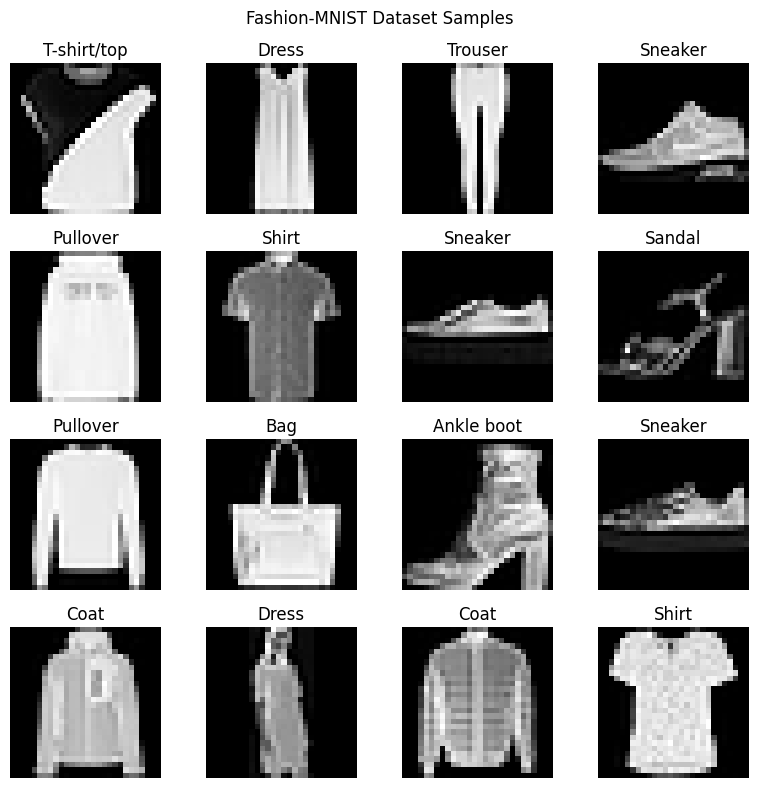

In [3]:
# Dataset

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]
images, labels = next(iter(train_loader))
fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    image = images[i].squeeze().numpy()
    label = labels[i].item()

    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(class_names[label])
    ax.axis("off")

plt.suptitle("Fashion-MNIST Dataset Samples")
plt.tight_layout()
plt.show()


In [4]:
# Vanilla AE -> Architecture

class VanillaAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        reconstructed = self.decoder(z)

        return reconstructed.view(-1, 1, 28, 28)

vanilla_ae = VanillaAE(
    latent_dim=LATENT_DIM
).to(DEVICE)

print(vanilla_ae)


VanillaAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)


In [5]:
# Vanilla AE -> Training

criterion = nn.MSELoss()

optimizer = optim.Adam(
    vanilla_ae.parameters(),
    lr=LEARNING_RATE
)
train_losses = []
val_losses = []
epoch_times = []

best_val_loss = float("inf")
best_vanilla_ae_state = None

for epoch in range(EPOCHS):

    start_time = time.perf_counter()
    vanilla_ae.train()
    total_train_loss = 0

    for images, _ in train_loader:
        images = images.to(DEVICE)

        optimizer.zero_grad()

        reconstructed = vanilla_ae(images)
        loss = criterion(reconstructed, images)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * images.size(0)

    avg_train_loss = total_train_loss / len(train_dataset)
    vanilla_ae.eval()
    total_val_loss = 0

    with torch.no_grad():
        for images, _ in val_loader:
            images = images.to(DEVICE)

            reconstructed = vanilla_ae(images)
            loss = criterion(reconstructed, images)

            total_val_loss += loss.item() * images.size(0)

    avg_val_loss = total_val_loss / len(val_dataset)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    epoch_time = time.perf_counter() - start_time
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    epoch_times.append(epoch_time)
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_vanilla_ae_state = snapshot_state_dict(vanilla_ae)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {avg_train_loss:.6f} | "
        f"Val Loss: {avg_val_loss:.6f} | "
        f"Time: {epoch_time:.2f}s"
    )

vanilla_ae.load_state_dict(best_vanilla_ae_state)
print("\nTraining Complete!")
print(f"Best Validation Loss: {best_val_loss:.6f}")
print(f"Average Epoch Time: {np.mean(epoch_times):.2f}s")


Epoch [1/20] | Train Loss: 0.031998 | Val Loss: 0.019579 | Time: 19.61s
Epoch [2/20] | Train Loss: 0.016718 | Val Loss: 0.015415 | Time: 11.87s
Epoch [3/20] | Train Loss: 0.014100 | Val Loss: 0.013381 | Time: 7.92s
Epoch [4/20] | Train Loss: 0.012462 | Val Loss: 0.012104 | Time: 7.13s
Epoch [5/20] | Train Loss: 0.011358 | Val Loss: 0.011416 | Time: 7.82s
Epoch [6/20] | Train Loss: 0.010595 | Val Loss: 0.010518 | Time: 7.29s
Epoch [7/20] | Train Loss: 0.009989 | Val Loss: 0.009937 | Time: 8.75s
Epoch [8/20] | Train Loss: 0.009473 | Val Loss: 0.009488 | Time: 7.92s
Epoch [9/20] | Train Loss: 0.009044 | Val Loss: 0.009136 | Time: 7.01s
Epoch [10/20] | Train Loss: 0.008697 | Val Loss: 0.008759 | Time: 7.89s
Epoch [11/20] | Train Loss: 0.008374 | Val Loss: 0.008578 | Time: 7.21s
Epoch [12/20] | Train Loss: 0.008089 | Val Loss: 0.008289 | Time: 7.85s
Epoch [13/20] | Train Loss: 0.007873 | Val Loss: 0.008198 | Time: 7.79s
Epoch [14/20] | Train Loss: 0.007675 | Val Loss: 0.007922 | Time: 7.02s

In [6]:
# Vanilla AE test evaluation
vanilla_ae.eval()

total_squared_error = 0
total_pixels = 0

psnr_values = []
ssim_values = []

with torch.no_grad():

    for images, _ in test_loader:

        images = images.to(DEVICE)
        reconstructed = vanilla_ae(images)
        squared_error = (reconstructed - images) ** 2
        total_squared_error += squared_error.sum().item()
        total_pixels += images.numel()
        mse_per_image = squared_error.mean(dim=(1, 2, 3))
        psnr_batch = 10 * torch.log10(
            1.0 / mse_per_image.clamp_min(1e-10)
        )

        psnr_values.extend(
            psnr_batch.cpu().numpy()
        )

        original_np = images.cpu().numpy()
        reconstructed_np = reconstructed.cpu().numpy()

        for i in range(len(images)):

            score = structural_similarity(
                original_np[i, 0],
                reconstructed_np[i, 0],
                data_range=1.0
            )

            ssim_values.append(score)
test_mse = total_squared_error / total_pixels
test_psnr = np.mean(psnr_values)
test_ssim = np.mean(ssim_values)

print("VANILLA AE TEST RESULTS")
print(f"Test MSE  : {test_mse:.6f}")
print(f"Test PSNR : {test_psnr:.4f}")
print(f"Test SSIM : {test_ssim:.6f}")


VANILLA AE TEST RESULTS
Test MSE  : 0.007096
Test PSNR : 22.5605
Test SSIM : 0.815026


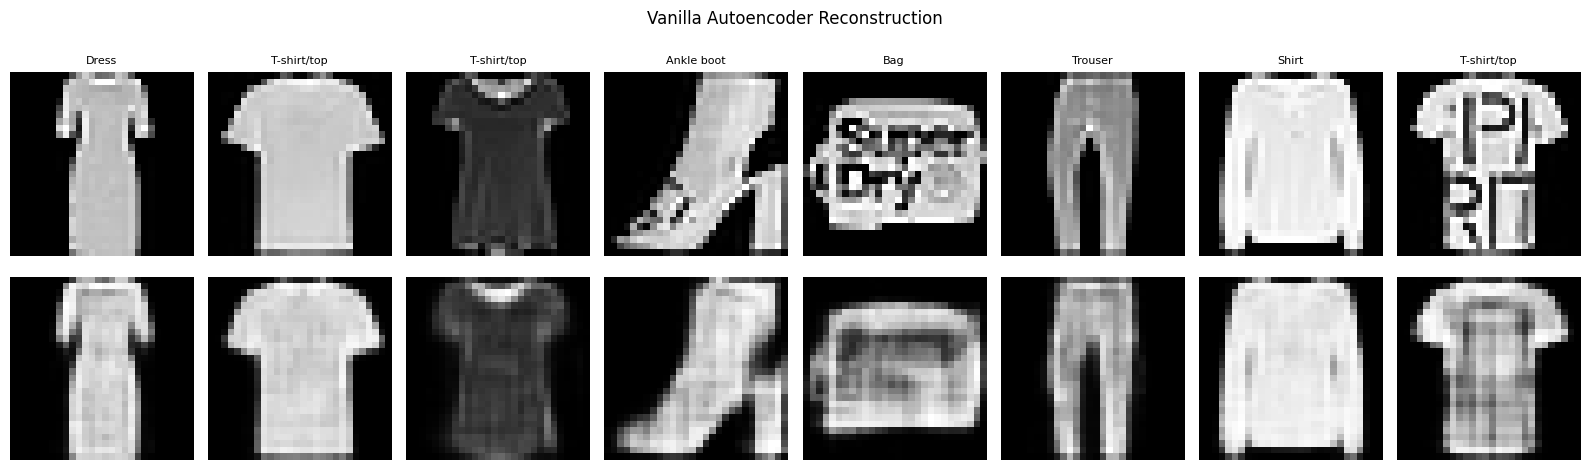

In [7]:
# Vanilla AE -> Reconstruction

vanilla_ae.eval()
comparison_images, comparison_labels = next(iter(test_loader))
comparison_images = comparison_images[:8].to(DEVICE)
comparison_labels = comparison_labels[:8]
with torch.no_grad():
    reconstructed_images = vanilla_ae(comparison_images)

fig, axes = plt.subplots(2, 8, figsize=(16, 5))

for i in range(8):

    original = comparison_images[i].cpu().squeeze().numpy()
    reconstructed = reconstructed_images[i].cpu().squeeze().numpy()
    axes[0, i].imshow(original, cmap="gray")
    axes[0, i].set_title(
        class_names[comparison_labels[i].item()],
        fontsize=8
    )
    axes[0, i].axis("off")
    axes[1, i].imshow(reconstructed, cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=10)
axes[1, 0].set_ylabel("Vanilla AE", fontsize=10)

plt.suptitle("Vanilla Autoencoder Reconstruction")
plt.tight_layout()
plt.show()


In [8]:
class SparseAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()

        # Encode
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, latent_dim),
            nn.ReLU()
        )

        # Decode
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)

        reconstructed = self.decoder(z)

        return reconstructed.view(-1, 1, 28, 28), z


# Sparse AE
sparse_ae = SparseAE(
    latent_dim=LATENT_DIM
).to(DEVICE)

print(sparse_ae)


SparseAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)


In [9]:
# Sparse AE -> Training

SPARSITY_LAMBDA = 0.0001

optimizer_sparse = optim.Adam(
    sparse_ae.parameters(),
    lr=LEARNING_RATE
)

criterion_sparse = nn.MSELoss()

sparse_train_losses = []
sparse_val_losses = []
sparse_epoch_times = []
sparse_penalties = []

best_sparse_val_loss = float("inf")
best_sparse_ae_state = None

for epoch in range(EPOCHS):

    start_time = time.perf_counter()
    sparse_ae.train()

    total_recon_loss = 0
    total_sparse_penalty = 0

    for images, _ in train_loader:
        images = images.to(DEVICE)
        optimizer_sparse.zero_grad()
        reconstructed, z = sparse_ae(images)
        recon_loss = criterion_sparse(
            reconstructed, images
        )

        sparsity_loss = z.abs().sum(dim=1).mean()

        total_loss = (
            recon_loss +
            SPARSITY_LAMBDA * sparsity_loss
        )

        total_loss.backward()
        optimizer_sparse.step()

        batch_size = images.size(0)

        total_recon_loss += recon_loss.item() * batch_size
        total_sparse_penalty += sparsity_loss.item() * batch_size

    avg_recon_loss = total_recon_loss / len(train_dataset)
    avg_sparse_penalty = (
        total_sparse_penalty / len(train_dataset)
    )
    sparse_ae.eval()

    total_val_loss = 0

    with torch.no_grad():

        for images, _ in val_loader:

            images = images.to(DEVICE)

            reconstructed, z = sparse_ae(images)

            loss = criterion_sparse(reconstructed, images)

            total_val_loss += loss.item() * images.size(0)

    avg_val_loss = total_val_loss / len(val_dataset)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    epoch_time = time.perf_counter() - start_time

    sparse_train_losses.append(avg_recon_loss)
    sparse_val_losses.append(avg_val_loss)
    sparse_epoch_times.append(epoch_time)
    sparse_penalties.append(avg_sparse_penalty)

    if avg_val_loss < best_sparse_val_loss:
        best_sparse_val_loss = avg_val_loss
        best_sparse_ae_state = snapshot_state_dict(sparse_ae)
    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train MSE: {avg_recon_loss:.6f} | "
        f"Val MSE: {avg_val_loss:.6f} | "
        f"L1: {avg_sparse_penalty:.4f} | "
        f"Time: {epoch_time:.2f}s"
  )

sparse_ae.load_state_dict(best_sparse_ae_state)
print("\nSparse AE Training Complete!")
print(f"Best Validation MSE: {best_sparse_val_loss:.6f}")
print(f"Average Epoch Time: {np.mean(sparse_epoch_times):.2f}s")
print(f"Sparsity Lambda: {SPARSITY_LAMBDA}")


Epoch [1/20] | Train MSE: 0.035841 | Val MSE: 0.021156 | L1: 24.7253 | Time: 7.92s
Epoch [2/20] | Train MSE: 0.018611 | Val MSE: 0.017215 | L1: 17.1505 | Time: 7.48s
Epoch [3/20] | Train MSE: 0.015936 | Val MSE: 0.015546 | L1: 15.3154 | Time: 7.97s
Epoch [4/20] | Train MSE: 0.014577 | Val MSE: 0.014331 | L1: 14.1915 | Time: 7.25s
Epoch [5/20] | Train MSE: 0.013687 | Val MSE: 0.013638 | L1: 13.4754 | Time: 8.00s
Epoch [6/20] | Train MSE: 0.013083 | Val MSE: 0.013133 | L1: 12.9443 | Time: 7.65s
Epoch [7/20] | Train MSE: 0.012554 | Val MSE: 0.012662 | L1: 12.5484 | Time: 7.41s
Epoch [8/20] | Train MSE: 0.012134 | Val MSE: 0.012214 | L1: 12.2213 | Time: 7.94s
Epoch [9/20] | Train MSE: 0.011773 | Val MSE: 0.011959 | L1: 11.8954 | Time: 7.24s
Epoch [10/20] | Train MSE: 0.011438 | Val MSE: 0.011584 | L1: 11.5966 | Time: 8.03s
Epoch [11/20] | Train MSE: 0.011171 | Val MSE: 0.011337 | L1: 11.2904 | Time: 7.59s
Epoch [12/20] | Train MSE: 0.010962 | Val MSE: 0.011111 | L1: 10.9713 | Time: 7.67s
E

In [10]:
# Sparse AE test evaluation

sparse_ae.eval()

total_squared_error = 0
total_pixels = 0

psnr_values = []
ssim_values = []

zero_count = 0
total_latent_values = 0

with torch.no_grad():

    for images, _ in test_loader:

        images = images.to(DEVICE)
        reconstructed, z = sparse_ae(images)
        squared_error = (reconstructed - images) ** 2
        total_squared_error += squared_error.sum().item()
        total_pixels += images.numel()
        mse_per_image = squared_error.mean(dim=(1, 2, 3))

        psnr_batch = 10 * torch.log10(
            1.0 / mse_per_image.clamp_min(1e-10)
        )

        psnr_values.extend(
            psnr_batch.cpu().numpy()
        )
        original_np = images.cpu().numpy()
        reconstructed_np = reconstructed.cpu().numpy()

        for i in range(len(images)):

            score = structural_similarity(
                original_np[i, 0],
                reconstructed_np[i, 0],
                data_range=1.0
            )

            ssim_values.append(score)
        zero_count += (z.abs() < 1e-6).sum().item()
        total_latent_values += z.numel()


# Final
sparse_test_mse = total_squared_error / total_pixels
sparse_test_psnr = np.mean(psnr_values)
sparse_test_ssim = np.mean(ssim_values)

sparsity_ratio = (
    zero_count / total_latent_values
) * 100

print("SPARSE AE TEST RESULTS")
print(f"Test MSE       : {sparse_test_mse:.6f}")
print(f"Test PSNR      : {sparse_test_psnr:.4f}")
print(f"Test SSIM      : {sparse_test_ssim:.6f}")
print(f"Sparsity Ratio : {sparsity_ratio:.2f}%")


SPARSE AE TEST RESULTS
Test MSE       : 0.009968
Test PSNR      : 20.9573
Test SSIM      : 0.755831
Sparsity Ratio : 53.56%


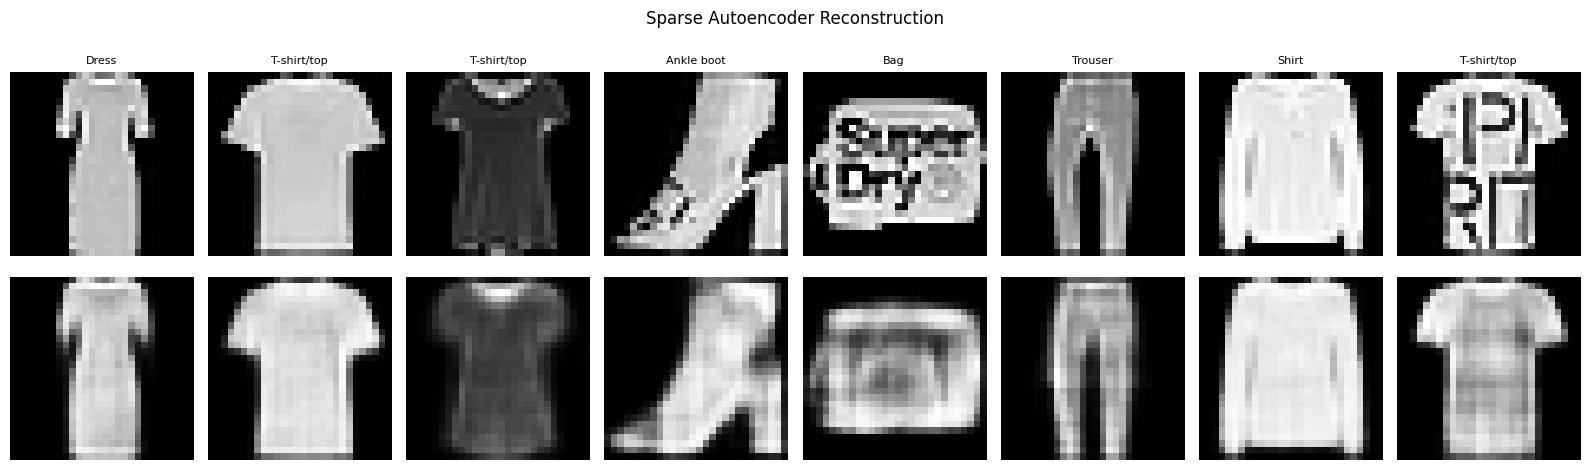

In [11]:
sparse_ae.eval()
images, labels = next(iter(test_loader))
images = images[:8].to(DEVICE)
labels = labels[:8]


# Reconstruct
with torch.no_grad():
    reconstructed, z = sparse_ae(images)
fig, axes = plt.subplots(2, 8, figsize=(16, 5))

for i in range(8):

    original = images[i].cpu().squeeze().numpy()
    reconstructed_img = (
        reconstructed[i].cpu().squeeze().numpy()
    )

    axes[0, i].imshow(original, cmap="gray")
    axes[0, i].set_title(
        class_names[labels[i].item()],
        fontsize=8
    )
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstructed_img, cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Sparse AE")

plt.suptitle("Sparse Autoencoder Reconstruction")
plt.tight_layout()
plt.show()


In [12]:
class VAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU()
        )
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)


        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    # Reparameterization
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)

        eps = torch.randn_like(std)

        z = mu + eps * std

        return z

    def forward(self, x):

        # Encode
        hidden = self.encoder(x)

        mu = self.fc_mu(hidden)
        logvar = self.fc_logvar(hidden)

        # latent vector
        z = self.reparameterize(mu, logvar)

        # Decode
        reconstructed = self.decoder(z)
        reconstructed = reconstructed.view(-1, 1, 28, 28)
        return reconstructed, mu, logvar

vae = VAE(
    latent_dim=LATENT_DIM
).to(DEVICE)

print(vae)


VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
  )
  (fc_mu): Linear(in_features=256, out_features=64, bias=True)
  (fc_logvar): Linear(in_features=256, out_features=64, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)


In [13]:
# VAE
BETA = 1.0

optimizer_vae = optim.Adam(
    vae.parameters(),
    lr=LEARNING_RATE
)
vae_train_losses = []
vae_val_losses = []
vae_train_mse = []
vae_val_mse = []
vae_train_kl = []
vae_val_kl = []
vae_epoch_times = []
best_vae_val_loss = float("inf")
best_vae_state = None



for epoch in range(EPOCHS):

    start_time = time.perf_counter()
    vae.train()

    total_train_loss = 0
    total_train_recon = 0
    total_train_kl = 0



    for images, _ in train_loader:
        images = images.to(DEVICE)
        optimizer_vae.zero_grad()
        reconstructed, mu, logvar = vae(images)
        batch_size = images.size(0)
        recon_loss = F.mse_loss(
            reconstructed,
            images,
            reduction="sum"
        ) / batch_size



        kl_loss = -0.5 * torch.sum(
            1 + logvar - mu.pow(2) - logvar.exp()
        ) / batch_size




        loss = recon_loss + BETA * kl_loss
        loss.backward()
        optimizer_vae.step()
        total_train_loss += loss.item() * batch_size
        total_train_recon += (
            F.mse_loss(reconstructed, images).item()
            * batch_size
        )
        total_train_kl += kl_loss.item() * batch_size


    avg_train_loss = total_train_loss / len(train_dataset)
    avg_train_recon = total_train_recon / len(train_dataset)
    avg_train_kl = total_train_kl / len(train_dataset)


    vae.eval()
    total_val_loss = 0
    total_val_recon = 0
    total_val_kl = 0

    with torch.no_grad():
        for images, _ in val_loader:
            images = images.to(DEVICE)
            reconstructed, mu, logvar = vae(images)
            batch_size = images.size(0)
            recon_loss = F.mse_loss(
                reconstructed,
                images,
                reduction="sum"
            ) / batch_size

            kl_loss = -0.5 * torch.sum(
                1 + logvar - mu.pow(2) - logvar.exp()
            ) / batch_size

            loss = recon_loss + BETA * kl_loss

            total_val_loss += loss.item() * batch_size
            total_val_recon += (
                F.mse_loss(reconstructed, images).item()
                * batch_size
            )
            total_val_kl += kl_loss.item() * batch_size

    avg_val_loss = total_val_loss / len(val_dataset)
    avg_val_recon = total_val_recon / len(val_dataset)
    avg_val_kl = total_val_kl / len(val_dataset)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    epoch_time = time.perf_counter() - start_time

    # History
    vae_train_losses.append(avg_train_loss)
    vae_val_losses.append(avg_val_loss)
    vae_train_mse.append(avg_train_recon)
    vae_val_mse.append(avg_val_recon)
    vae_train_kl.append(avg_train_kl)
    vae_val_kl.append(avg_val_kl)
    vae_epoch_times.append(epoch_time)

    if avg_val_loss < best_vae_val_loss:
        best_vae_val_loss = avg_val_loss
        best_vae_state = snapshot_state_dict(vae)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Train MSE: {avg_train_recon:.6f} | "
        f"KL: {avg_train_kl:.4f} | "
        f"Time: {epoch_time:.2f}s"
    )

vae.load_state_dict(best_vae_state)
print("\nVAE Training Complete!")
print(f"Best Validation Loss: {best_vae_val_loss:.4f}")
print(f"Average Epoch Time: {np.mean(vae_epoch_times):.2f}s")


Epoch [1/20] | Train Loss: 45.1525 | Val Loss: 36.2265 | Train MSE: 0.049166 | KL: 6.6062 | Time: 8.44s
Epoch [2/20] | Train Loss: 32.9999 | Val Loss: 30.7106 | Train MSE: 0.032051 | KL: 7.8723 | Time: 7.62s
Epoch [3/20] | Train Loss: 29.3278 | Val Loss: 28.5319 | Train MSE: 0.027945 | KL: 7.4190 | Time: 8.37s
Epoch [4/20] | Train Loss: 27.9819 | Val Loss: 27.7056 | Train MSE: 0.026181 | KL: 7.4558 | Time: 8.43s
Epoch [5/20] | Train Loss: 27.2556 | Val Loss: 27.1219 | Train MSE: 0.025105 | KL: 7.5732 | Time: 7.65s
Epoch [6/20] | Train Loss: 26.7586 | Val Loss: 26.6866 | Train MSE: 0.024372 | KL: 7.6509 | Time: 8.29s
Epoch [7/20] | Train Loss: 26.4205 | Val Loss: 26.3567 | Train MSE: 0.023868 | KL: 7.7083 | Time: 7.98s
Epoch [8/20] | Train Loss: 26.1516 | Val Loss: 26.1633 | Train MSE: 0.023479 | KL: 7.7441 | Time: 8.02s
Epoch [9/20] | Train Loss: 25.9534 | Val Loss: 26.1858 | Train MSE: 0.023175 | KL: 7.7845 | Time: 8.37s
Epoch [10/20] | Train Loss: 25.7667 | Val Loss: 25.7815 | Train 

In [14]:
# VAE test evaluation

vae.eval()

total_squared_error = 0
total_pixels = 0

psnr_values = []
ssim_values = []
kl_values = []

with torch.no_grad():

    for images, _ in test_loader:

        images = images.to(DEVICE)

        # Encode
        hidden = vae.encoder(images)

        mu = vae.fc_mu(hidden)
        logvar = vae.fc_logvar(hidden)


        reconstructed = vae.decoder(mu)

        reconstructed = reconstructed.view(
            -1, 1, 28, 28
        )


        squared_error = (reconstructed - images) ** 2
        total_squared_error += squared_error.sum().item()
        total_pixels += images.numel()

        mse_per_image = squared_error.mean(dim=(1, 2, 3))
        psnr_batch = 10 * torch.log10(
            1.0 / mse_per_image.clamp_min(1e-10)
        )

        psnr_values.extend(
            psnr_batch.cpu().numpy()
        )

        # SSIM
        original_np = images.cpu().numpy()
        reconstructed_np = reconstructed.cpu().numpy()

        for i in range(len(images)):

            score = structural_similarity(
                original_np[i, 0],
                reconstructed_np[i, 0],
                data_range=1.0
            )

            ssim_values.append(score)

        kl = -0.5 * torch.sum(
            1 + logvar - mu.pow(2) - logvar.exp(),
            dim=1
        )

        kl_values.extend(kl.cpu().numpy())


# Metrics
vae_test_mse = total_squared_error / total_pixels
vae_test_psnr = np.mean(psnr_values)
vae_test_ssim = np.mean(ssim_values)
vae_test_kl = np.mean(kl_values)

print("VAE TEST RESULTS")
print(f"Test MSE  : {vae_test_mse:.6f}")
print(f"Test PSNR : {vae_test_psnr:.4f}")
print(f"Test SSIM : {vae_test_ssim:.6f}")
print(f"Test KL   : {vae_test_kl:.4f}")


VAE TEST RESULTS
Test MSE  : 0.017914
Test PSNR : 18.1377
Test SSIM : 0.632443
Test KL   : 8.2964


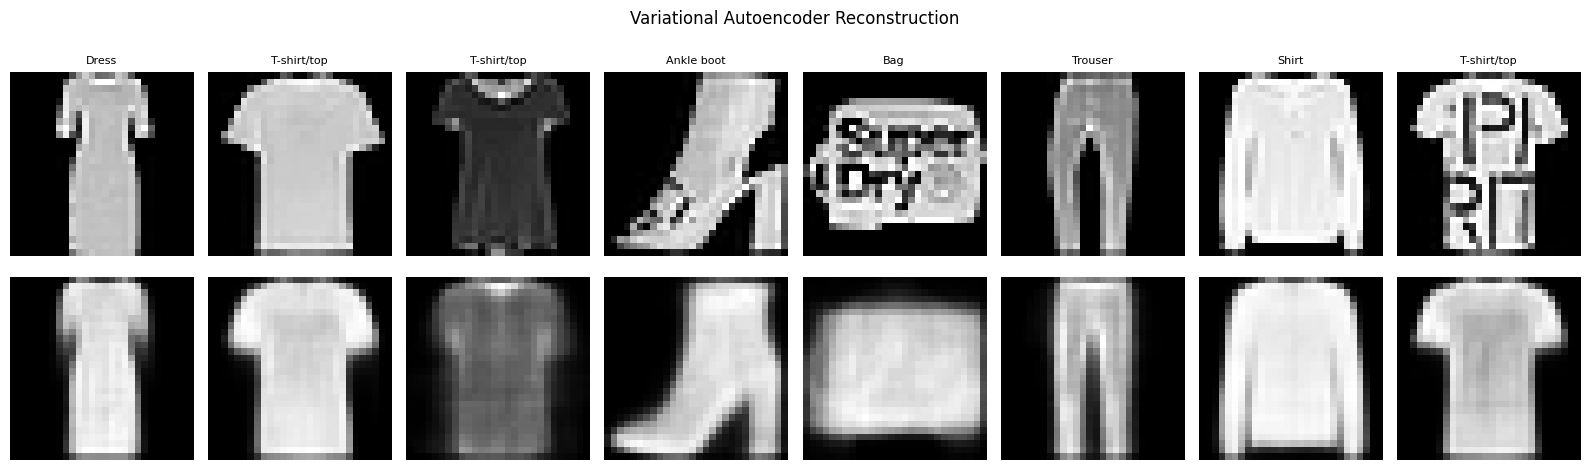

In [15]:
# Vanilla GAN
vae.eval()
images, labels = next(iter(test_loader))

images = images[:8].to(DEVICE)
labels = labels[:8]

with torch.no_grad():

    # Encode
    hidden = vae.encoder(images)

    mu = vae.fc_mu(hidden)

    reconstructed = vae.decoder(mu)

    reconstructed = reconstructed.view(
        -1, 1, 28, 28
    )

fig, axes = plt.subplots(2, 8, figsize=(16, 5))

for i in range(8):

    original = images[i].cpu().squeeze().numpy()
    reconstructed_img = (
        reconstructed[i].cpu().squeeze().numpy()
    )

    axes[0, i].imshow(original, cmap="gray")
    axes[0, i].set_title(
        class_names[labels[i].item()],
        fontsize=8
    )
    axes[0, i].axis("off")

    axes[1, i].imshow(
        reconstructed_img,
        cmap="gray"
    )
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("VAE")

plt.suptitle("Variational Autoencoder Reconstruction")
plt.tight_layout()
plt.show()


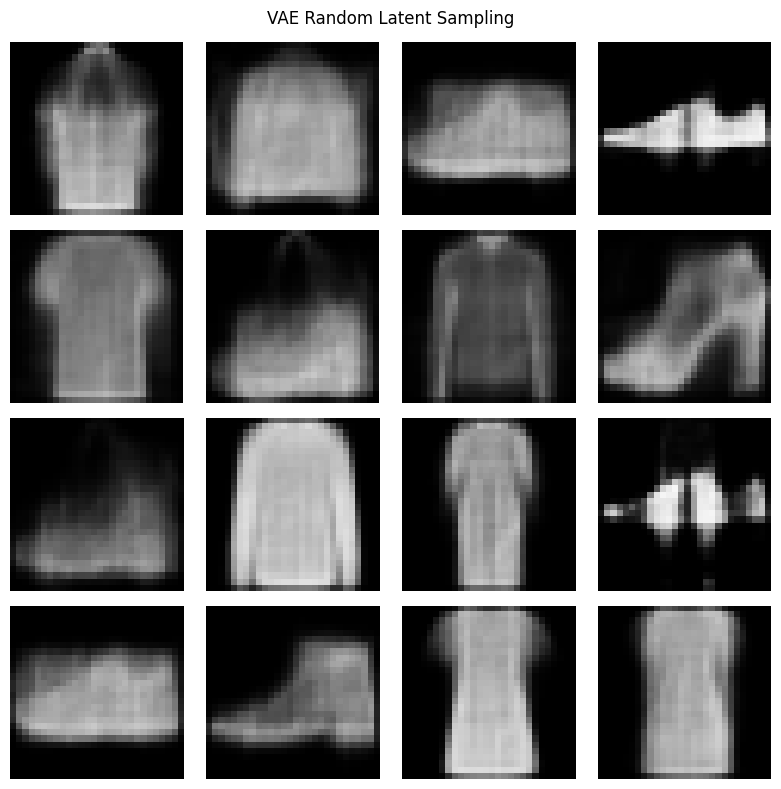

In [16]:
# VAE -> Sampling

vae.eval()

NUM_SAMPLES = 16

with torch.no_grad():

    z = torch.randn(
        NUM_SAMPLES,
        LATENT_DIM
    ).to(DEVICE)


    generated_images = vae.decoder(z)
    generated_images = generated_images.view(-1, 1, 28, 28)


fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):

    image = generated_images[i].cpu().squeeze().numpy()
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.axis("off")

plt.suptitle("VAE Random Latent Sampling")
plt.tight_layout()
plt.show()


In [17]:

# Generator
GAN_LATENT_DIM = 100
class Generator(nn.Module):

    def __init__(self, latent_dim=100):
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),

            nn.Linear(256, 512),
            nn.ReLU(),

            nn.Linear(512, 784),
            nn.Sigmoid()
        )

    def forward(self, z):

        generated = self.model(z)

        return generated.view(-1, 1, 28, 28)

# Discriminator
class Discriminator(nn.Module):

    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(
            nn.Flatten(),

            nn.Linear(784, 512),
            nn.LeakyReLU(0.2),

            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),

            nn.Linear(256, 1)
        )

    def forward(self, x):

        return self.model(x)

generator = Generator(
    GAN_LATENT_DIM
).to(DEVICE)

discriminator = Discriminator().to(DEVICE)

print("GENERATOR")
print(generator)

print("\nDISCRIMINATOR")
print(discriminator)


GENERATOR
Generator(
  (model): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

DISCRIMINATOR
Discriminator(
  (model): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=512, bias=True)
    (2): LeakyReLU(negative_slope=0.2)
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): LeakyReLU(negative_slope=0.2)
    (5): Linear(in_features=256, out_features=1, bias=True)
  )
)


In [18]:
# Vanilla GAN -> Optimizer

GAN_LR = 0.0002
GAN_BETAS = (0.5, 0.999)

# Loss function
gan_criterion = nn.BCEWithLogitsLoss()

optimizer_G = optim.Adam(
    generator.parameters(),
    lr=GAN_LR,
    betas=GAN_BETAS
)

optimizer_D = optim.Adam(
    discriminator.parameters(),
    lr=GAN_LR,
    betas=GAN_BETAS
)

print("GAN Learning Rate:", GAN_LR)
print("GAN Betas:", GAN_BETAS)


GAN Learning Rate: 0.0002
GAN Betas: (0.5, 0.999)


In [19]:
#DCGAN
GAN_EPOCHS = 20

gan_g_losses = []
gan_d_losses = []
gan_epoch_times = []

fixed_noise = torch.randn(
    16,
    GAN_LATENT_DIM,
    device=DEVICE
)

for epoch in range(GAN_EPOCHS):

    start_time = time.perf_counter()

    generator.train()
    discriminator.train()

    total_g_loss = 0
    total_d_loss = 0

    for images, _ in train_loader:

        images = images.to(DEVICE)

        batch_size = images.size(0)

        real_labels = torch.ones(
            batch_size, 1, device=DEVICE
        )

        fake_labels = torch.zeros(
            batch_size, 1, device=DEVICE
        )

        # Discriminator Train

        optimizer_D.zero_grad()

        real_output = discriminator(images)

        d_real_loss = gan_criterion(
            real_output, real_labels
        )

        noise = torch.randn(
            batch_size,
            GAN_LATENT_DIM,
            device=DEVICE
        )

        fake_images = generator(noise)

        fake_output = discriminator(
            fake_images.detach()
        )

        d_fake_loss = gan_criterion(
            fake_output, fake_labels
        )

        d_loss = (
            d_real_loss + d_fake_loss
        ) / 2

        d_loss.backward()
        optimizer_D.step()

        # Gen Train

        optimizer_G.zero_grad()

        for param in discriminator.parameters():
            param.requires_grad_(False)

        noise = torch.randn(
            batch_size,
            GAN_LATENT_DIM,
            device=DEVICE
        )

        generated_images = generator(noise)

        output = discriminator(generated_images)

        g_loss = gan_criterion(
            output, real_labels
        )

        g_loss.backward()
        optimizer_G.step()

        for param in discriminator.parameters():
            param.requires_grad_(True)

        # Loss
        total_d_loss += d_loss.item()
        total_g_loss += g_loss.item()

    avg_d_loss = total_d_loss / len(train_loader)
    avg_g_loss = total_g_loss / len(train_loader)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    epoch_time = time.perf_counter() - start_time

    gan_d_losses.append(avg_d_loss)
    gan_g_losses.append(avg_g_loss)
    gan_epoch_times.append(epoch_time)

    print(
        f"Epoch [{epoch+1}/{GAN_EPOCHS}] | "
        f"D Loss: {avg_d_loss:.4f} | "
        f"G Loss: {avg_g_loss:.4f} | "
        f"Time: {epoch_time:.2f}s"
    )

print("\nVanilla GAN Training Complete!")
print(f"Average Epoch Time: {np.mean(gan_epoch_times):.2f}s")


Epoch [1/20] | D Loss: 0.2581 | G Loss: 2.5358 | Time: 8.49s
Epoch [2/20] | D Loss: 0.1544 | G Loss: 4.1766 | Time: 7.70s
Epoch [3/20] | D Loss: 0.1106 | G Loss: 4.3075 | Time: 8.43s
Epoch [4/20] | D Loss: 0.1633 | G Loss: 4.2698 | Time: 8.04s
Epoch [5/20] | D Loss: 0.1930 | G Loss: 3.8103 | Time: 8.06s
Epoch [6/20] | D Loss: 0.2227 | G Loss: 3.2779 | Time: 8.36s
Epoch [7/20] | D Loss: 0.2573 | G Loss: 3.2386 | Time: 7.80s
Epoch [8/20] | D Loss: 0.3346 | G Loss: 2.4763 | Time: 8.27s
Epoch [9/20] | D Loss: 0.3580 | G Loss: 2.1941 | Time: 8.58s
Epoch [10/20] | D Loss: 0.3837 | G Loss: 2.1615 | Time: 7.94s
Epoch [11/20] | D Loss: 0.4110 | G Loss: 1.9287 | Time: 8.55s
Epoch [12/20] | D Loss: 0.4253 | G Loss: 1.7930 | Time: 8.47s
Epoch [13/20] | D Loss: 0.4446 | G Loss: 1.7287 | Time: 7.72s
Epoch [14/20] | D Loss: 0.4548 | G Loss: 1.7477 | Time: 8.51s
Epoch [15/20] | D Loss: 0.4636 | G Loss: 1.6243 | Time: 8.06s
Epoch [16/20] | D Loss: 0.4770 | G Loss: 1.5727 | Time: 8.05s
Epoch [17/20] | D

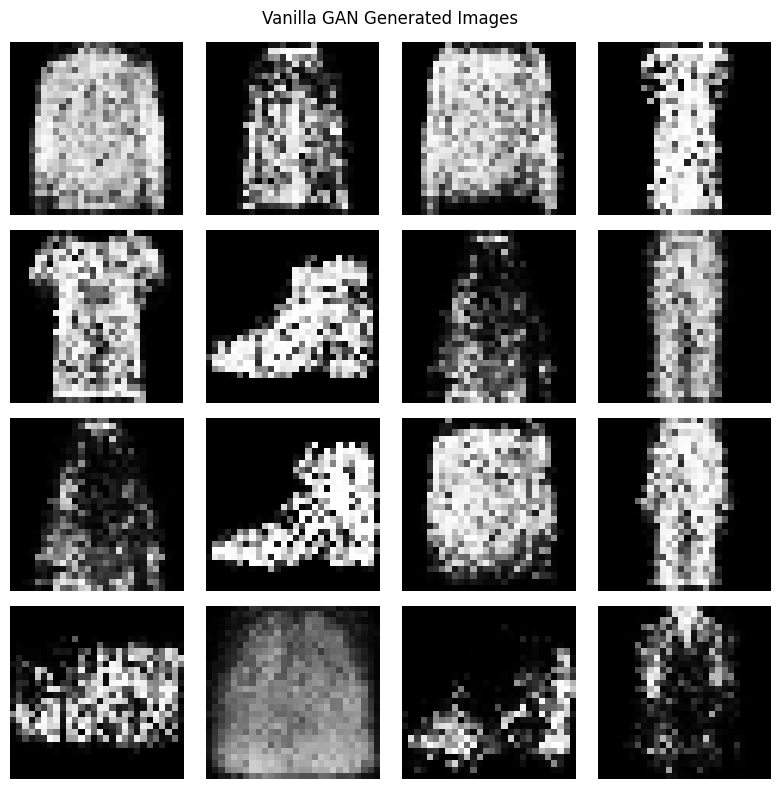

In [20]:
# Vanilla GAN -> Sampling

generator.eval()

with torch.no_grad():

    generated_images = generator(fixed_noise)

fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):

    image = generated_images[i].cpu().squeeze().numpy()

    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.axis("off")

plt.suptitle("Vanilla GAN Generated Images")
plt.tight_layout()
plt.show()


In [21]:
# DCGAN
DCGAN_LATENT_DIM = 100

# Generator

class DCGenerator(nn.Module):

    def __init__(self, latent_dim=100):
        super().__init__()

        self.model = nn.Sequential(

            # 100 x 1 x 1 -> 128 x 7 x 7
            nn.ConvTranspose2d(
                latent_dim, 128,
                kernel_size=7,
                stride=1,
                padding=0,
                bias=False
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(True),

            # 128 x 7 x 7 -> 64 x 14 x 14
            nn.ConvTranspose2d(
                128, 64,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(True),

            # 64 x 14 x 14 -> 1 x 28 x 28
            nn.ConvTranspose2d(
                64, 1,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.Sigmoid()
        )

    def forward(self, z):

        z = z.view(-1, DCGAN_LATENT_DIM, 1, 1)

        return self.model(z)


# Discriminator

class DCDiscriminator(nn.Module):

    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(

            # 1 x 28 x 28 -> 64 x 14 x 14
            nn.Conv2d(
                1, 64,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.LeakyReLU(0.2, inplace=True),

            # 64 x 14 x 14 -> 128 x 7 x 7
            nn.Conv2d(
                64, 128,
                kernel_size=4,
                stride=2,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            # 128 x 7 x 7 -> 1 x 1 x 1
            nn.Conv2d(
                128, 1,
                kernel_size=7,
                stride=1,
                padding=0
            )
        )

    def forward(self, x):

        output = self.model(x)

        return output.view(-1, 1)


dc_generator = DCGenerator(
    DCGAN_LATENT_DIM
).to(DEVICE)

dc_discriminator = DCDiscriminator().to(DEVICE)

print("DCGAN GENERATOR")
print(dc_generator)

print("\nDCGAN DISCRIMINATOR")
print(dc_discriminator)


DCGAN GENERATOR
DCGenerator(
  (model): Sequential(
    (0): ConvTranspose2d(100, 128, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): Sigmoid()
  )
)

DCGAN DISCRIMINATOR
DCDiscriminator(
  (model): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (4): LeakyR

In [22]:
# Test Generator
dc_generator.eval()
dc_discriminator.eval()

test_noise = torch.randn(
    4, DCGAN_LATENT_DIM, device=DEVICE
)

# Test Discriminator
with torch.no_grad():
    generated = dc_generator(test_noise)
    discriminator_output = dc_discriminator(generated)

print("Noise Shape:", test_noise.shape)
print("Generated Image Shape:", generated.shape)
print("Discriminator Output Shape:", discriminator_output.shape)

dc_generator.train()
dc_discriminator.train()


Noise Shape: torch.Size([4, 100])
Generated Image Shape: torch.Size([4, 1, 28, 28])
Discriminator Output Shape: torch.Size([4, 1])


DCDiscriminator(
  (model): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Conv2d(128, 1, kernel_size=(7, 7), stride=(1, 1))
  )
)

In [23]:
# DCGAN -> Optimizer

def weights_init(m):

    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):

        nn.init.normal_(m.weight.data, 0.0, 0.02)

    elif isinstance(m, nn.BatchNorm2d):

        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

dc_generator.apply(weights_init)
dc_discriminator.apply(weights_init)

DCGAN_LR = 0.0002
DCGAN_BETAS = (0.5, 0.999)

dcgan_criterion = nn.BCEWithLogitsLoss()

optimizer_dc_G = optim.Adam(
    dc_generator.parameters(),
    lr=DCGAN_LR,
    betas=DCGAN_BETAS
)

optimizer_dc_D = optim.Adam(
    dc_discriminator.parameters(),
    lr=DCGAN_LR,
    betas=DCGAN_BETAS
)

print("DCGAN Learning Rate:", DCGAN_LR)
print("DCGAN Betas:", DCGAN_BETAS)
print("Weight Initialization: Normal(0, 0.02)")


DCGAN Learning Rate: 0.0002
DCGAN Betas: (0.5, 0.999)
Weight Initialization: Normal(0, 0.02)


In [24]:
# DDPM
DCGAN_EPOCHS = 20

dc_g_losses = []
dc_d_losses = []
dc_epoch_times = []

dc_fixed_noise = torch.randn(
    16,
    DCGAN_LATENT_DIM,
    device=DEVICE
)

for epoch in range(DCGAN_EPOCHS):

    start_time = time.perf_counter()

    dc_generator.train()
    dc_discriminator.train()

    total_g_loss = 0
    total_d_loss = 0

    for images, _ in train_loader:

        images = images.to(DEVICE)

        batch_size = images.size(0)

        real_labels = torch.ones(
            batch_size, 1, device=DEVICE
        )

        fake_labels = torch.zeros(
            batch_size, 1, device=DEVICE
        )

        # Train Disc

        optimizer_dc_D.zero_grad()
        real_output = dc_discriminator(images)

        d_real_loss = dcgan_criterion(
            real_output, real_labels
        )

        noise = torch.randn(
            batch_size,
            DCGAN_LATENT_DIM,
            device=DEVICE
        )

        fake_images = dc_generator(noise)

        fake_output = dc_discriminator(
            fake_images.detach()
        )

        d_fake_loss = dcgan_criterion(
            fake_output, fake_labels
        )

        # Loss Disc
        d_loss = (
            d_real_loss + d_fake_loss
        ) / 2

        d_loss.backward()
        optimizer_dc_D.step()

        # Gen Train

        optimizer_dc_G.zero_grad()

        for param in dc_discriminator.parameters():
            param.requires_grad_(False)

        noise = torch.randn(
            batch_size,
            DCGAN_LATENT_DIM,
            device=DEVICE
        )

        generated_images = dc_generator(noise)

        output = dc_discriminator(generated_images)

        g_loss = dcgan_criterion(
            output, real_labels
        )

        g_loss.backward()
        optimizer_dc_G.step()

        for param in dc_discriminator.parameters():
            param.requires_grad_(True)

        total_d_loss += d_loss.item()
        total_g_loss += g_loss.item()

    avg_d_loss = total_d_loss / len(train_loader)
    avg_g_loss = total_g_loss / len(train_loader)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    epoch_time = time.perf_counter() - start_time

    dc_d_losses.append(avg_d_loss)
    dc_g_losses.append(avg_g_loss)
    dc_epoch_times.append(epoch_time)

    print(
        f"Epoch [{epoch+1}/{DCGAN_EPOCHS}] | "
        f"D Loss: {avg_d_loss:.4f} | "
        f"G Loss: {avg_g_loss:.4f} | "
        f"Time: {epoch_time:.2f}s"
    )

print("\nDCGAN Training Complete!")
print(f"Average Epoch Time: {np.mean(dc_epoch_times):.2f}s")


Epoch [1/20] | D Loss: 0.1518 | G Loss: 3.0368 | Time: 13.89s
Epoch [2/20] | D Loss: 0.2482 | G Loss: 2.1484 | Time: 13.70s
Epoch [3/20] | D Loss: 0.3111 | G Loss: 1.8237 | Time: 14.02s
Epoch [4/20] | D Loss: 0.3565 | G Loss: 1.6520 | Time: 13.89s
Epoch [5/20] | D Loss: 0.3947 | G Loss: 1.5344 | Time: 13.79s
Epoch [6/20] | D Loss: 0.4140 | G Loss: 1.4645 | Time: 13.65s
Epoch [7/20] | D Loss: 0.4232 | G Loss: 1.4298 | Time: 13.82s
Epoch [8/20] | D Loss: 0.4327 | G Loss: 1.4141 | Time: 13.95s
Epoch [9/20] | D Loss: 0.4392 | G Loss: 1.3926 | Time: 13.90s
Epoch [10/20] | D Loss: 0.4526 | G Loss: 1.3783 | Time: 13.94s
Epoch [11/20] | D Loss: 0.4621 | G Loss: 1.3486 | Time: 13.87s
Epoch [12/20] | D Loss: 0.4717 | G Loss: 1.3166 | Time: 13.76s
Epoch [13/20] | D Loss: 0.4773 | G Loss: 1.3095 | Time: 13.81s
Epoch [14/20] | D Loss: 0.4845 | G Loss: 1.2939 | Time: 13.80s
Epoch [15/20] | D Loss: 0.4906 | G Loss: 1.2732 | Time: 13.92s
Epoch [16/20] | D Loss: 0.4964 | G Loss: 1.2665 | Time: 14.03s
E

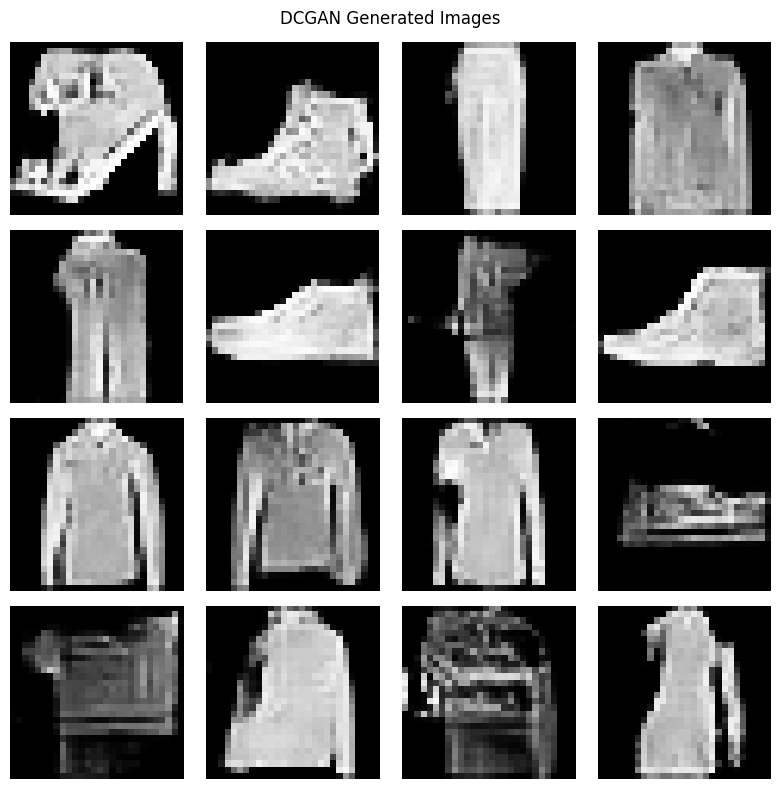

In [25]:
# DCGAN -> Sampling

dc_generator.eval()
with torch.no_grad():

    generated_images = dc_generator(dc_fixed_noise)
fig, axes = plt.subplots(4, 4, figsize=(8, 8))

for i, ax in enumerate(axes.flat):

    image = generated_images[i].cpu().squeeze().numpy()

    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.axis("off")

plt.suptitle("DCGAN Generated Images")
plt.tight_layout()
plt.show()


In [26]:
# DDPM -> Embeddings

class SinusoidalPosEmb(nn.Module):

    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):

        half_dim = self.dim // 2

        emb_factor = math.log(10000) / (half_dim - 1)

        emb = torch.exp(
            torch.arange(
                half_dim,
                device=t.device
            ) * -emb_factor
        )

        emb = t.float()[:, None] * emb[None, :]

        emb = torch.cat(
            [emb.sin(), emb.cos()],
            dim=1
        )

        return emb

# Res block
class ResBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        time_emb_dim
    ):
        super().__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.GroupNorm(8, out_channels),
            nn.SiLU()
        )

        self.time_mlp = nn.Sequential(
            nn.SiLU(),
            nn.Linear(
                time_emb_dim,
                out_channels
            )
        )

        self.block2 = nn.Sequential(
            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.GroupNorm(8, out_channels)
        )

        self.residual_conv = (
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1
            )
            if in_channels != out_channels
            else nn.Identity()
        )

    def forward(self, x, t_emb):

        h = self.block1(x)

        time_emb = self.time_mlp(t_emb)

        h = h + time_emb[:, :, None, None]

        h = self.block2(h)

        return F.silu(
            h + self.residual_conv(x)
        )


In [27]:
# DDPM -> Architecture

class DDPMUNet(nn.Module):

    def __init__(self, time_emb_dim=128):
        super().__init__()

        self.time_mlp = nn.Sequential(
            SinusoidalPosEmb(time_emb_dim),
            nn.Linear(time_emb_dim, time_emb_dim),
            nn.SiLU(),
            nn.Linear(time_emb_dim, time_emb_dim)
        )

        self.init_conv = nn.Conv2d(
            1, 32, kernel_size=3, padding=1
        )

        # Encoder
        self.down_block1 = ResBlock(
            32, 32, time_emb_dim
        )

        self.downsample1 = nn.Conv2d(
            32, 64, kernel_size=4,
            stride=2, padding=1
        )

        self.down_block2 = ResBlock(
            64, 64, time_emb_dim
        )

        self.downsample2 = nn.Conv2d(
            64, 128, kernel_size=4,
            stride=2, padding=1
        )

        self.mid_block = ResBlock(
            128, 128, time_emb_dim
        )

        # Decoder
        self.upsample1 = nn.ConvTranspose2d(
            128, 64, kernel_size=4,
            stride=2, padding=1
        )

        self.up_block1 = ResBlock(
            128, 64, time_emb_dim
        )

        self.upsample2 = nn.ConvTranspose2d(
            64, 32, kernel_size=4,
            stride=2, padding=1
        )

        self.up_block2 = ResBlock(
            64, 32, time_emb_dim
        )

        self.output_conv = nn.Conv2d(
            32, 1, kernel_size=1
        )

    def forward(self, x, t):

        t_emb = self.time_mlp(t)
        x = self.init_conv(x)

        # Encode
        h1 = self.down_block1(x, t_emb)
        x = self.downsample1(h1)

        h2 = self.down_block2(x, t_emb)
        x = self.downsample2(h2)

        x = self.mid_block(x, t_emb)

        # Decode + Skip
        x = self.upsample1(x)

        x = torch.cat([x, h2], dim=1)
        x = self.up_block1(x, t_emb)

        x = self.upsample2(x)

        x = torch.cat([x, h1], dim=1)
        x = self.up_block2(x, t_emb)

        return self.output_conv(x)

ddpm_model = DDPMUNet(
    time_emb_dim=128
).to(DEVICE)

print(ddpm_model)


DDPMUNet(
  (time_mlp): Sequential(
    (0): SinusoidalPosEmb()
    (1): Linear(in_features=128, out_features=128, bias=True)
    (2): SiLU()
    (3): Linear(in_features=128, out_features=128, bias=True)
  )
  (init_conv): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (down_block1): ResBlock(
    (block1): Sequential(
      (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
      (2): SiLU()
    )
    (time_mlp): Sequential(
      (0): SiLU()
      (1): Linear(in_features=128, out_features=32, bias=True)
    )
    (block2): Sequential(
      (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
    )
    (residual_conv): Identity()
  )
  (downsample1): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
  (down_block2): ResBlock(
    (block1): Sequential(
      (0): Conv2d(64, 64, kernel_siz

In [28]:
# Test DDPM
test_images = torch.randn(
    4, 1, 28, 28
).to(DEVICE)

test_timesteps = torch.randint(
    0, 1000, (4,)
).to(DEVICE)

with torch.no_grad():

    predicted_noise = ddpm_model(
        test_images,
        test_timesteps
    )

print("Input Shape:", test_images.shape)
print("Timestep Shape:", test_timesteps.shape)
print("Predicted Noise Shape:", predicted_noise.shape)


Input Shape: torch.Size([4, 1, 28, 28])
Timestep Shape: torch.Size([4])
Predicted Noise Shape: torch.Size([4, 1, 28, 28])


In [29]:
# DDPM NOISE

TIMESTEPS = 1000

BETA_START = 0.0001
BETA_END = 0.02

betas = torch.linspace(
    BETA_START,
    BETA_END,
    TIMESTEPS
).to(DEVICE)

alphas = 1.0 - betas

alphas_cumprod = torch.cumprod(
    alphas,
    dim=0
)

sqrt_alphas_cumprod = torch.sqrt(
    alphas_cumprod
)

sqrt_one_minus_alphas_cumprod = torch.sqrt(
    1.0 - alphas_cumprod
)

print("DDPM NOISE SCHEDULE")
print("Timesteps:", TIMESTEPS)
print("Beta Start:", betas[0].item())
print("Beta End:", betas[-1].item())
print("Alpha Start:", alphas[0].item())
print("Alpha Bar Start:", alphas_cumprod[0].item())
print("Alpha Bar End:", alphas_cumprod[-1].item())


DDPM NOISE SCHEDULE
Timesteps: 1000
Beta Start: 9.999999747378752e-05
Beta End: 0.019999999552965164
Alpha Start: 0.9998999834060669
Alpha Bar Start: 0.9998999834060669
Alpha Bar End: 4.035829260828905e-05


In [30]:
# Forward Diffusion
def extract(schedule, t, x_shape):

    values = schedule.gather(0, t)

    return values.reshape(
        t.shape[0],
        *([1] * (len(x_shape) - 1))
    )


def q_sample(x_start, t, noise=None):

    if noise is None:
        noise = torch.randn_like(x_start)

    sqrt_alpha_bar = extract(
        sqrt_alphas_cumprod,
        t,
        x_start.shape
    )

    sqrt_one_minus_alpha_bar = extract(
        sqrt_one_minus_alphas_cumprod,
        t,
        x_start.shape
    )

    noisy_images = (
        sqrt_alpha_bar * x_start
        + sqrt_one_minus_alpha_bar * noise
    )

    return noisy_images, noise


print("Forward Diffusion Function Ready!")

Forward Diffusion Function Ready!


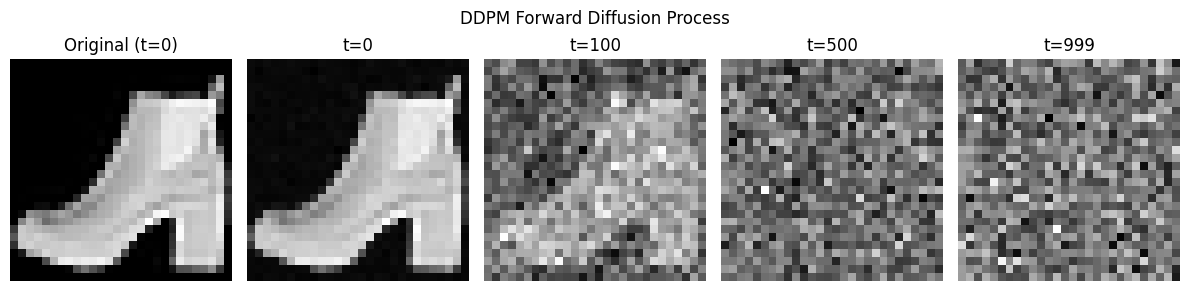

In [31]:
# DDPM -> Forward Diffusion Preview

images, _ = next(iter(train_loader))

original_image = images[:1].to(DEVICE)

t_values = torch.tensor(
    [0, 100, 500, 999],
    device=DEVICE
)

test_batch = original_image.repeat(4, 1, 1, 1)

with torch.no_grad():

    noisy_images, _ = q_sample(
        test_batch,
        t_values
    )


fig, axes = plt.subplots(1, 5, figsize=(12, 3))

axes[0].imshow(
    original_image[0].cpu().squeeze().numpy(),
    cmap="gray"
)
axes[0].set_title("Original (t=0)")
axes[0].axis("off")

for i in range(4):

    image = noisy_images[i].cpu().squeeze().numpy()

    axes[i+1].imshow(image, cmap="gray")
    axes[i+1].set_title(
        f"t={t_values[i].item()}"
    )
    axes[i+1].axis("off")

plt.suptitle("DDPM Forward Diffusion Process")
plt.tight_layout()
plt.show()


In [32]:
# DDPM Train

DDPM_EPOCHS = 20
DDPM_LR = 0.0002

# Loss function
ddpm_criterion = nn.MSELoss()

# Optimizer
optimizer_ddpm = optim.Adam(
    ddpm_model.parameters(),
    lr=DDPM_LR
)

ddpm_train_losses = []
ddpm_val_losses = []
ddpm_epoch_times = []

best_ddpm_val_loss = float("inf")
best_ddpm_state = None

print("DDPM CONFIGURATION")
print("Epochs:", DDPM_EPOCHS)
print("Learning Rate:", DDPM_LR)
print("Optimizer: Adam")
print("Loss Function: MSE")
print("Timesteps:", TIMESTEPS)


DDPM CONFIGURATION
Epochs: 20
Learning Rate: 0.0002
Optimizer: Adam
Loss Function: MSE
Timesteps: 1000


In [33]:
# Train
for epoch in range(DDPM_EPOCHS):

    start_time = time.perf_counter()

    ddpm_model.train()

    total_train_loss = 0

    for images, _ in train_loader:

        images = images.to(DEVICE)

        batch_size = images.size(0)

        t = torch.randint(
            0,
            TIMESTEPS,
            (batch_size,),
            device=DEVICE
        ).long()
        noisy_images, noise = q_sample(
            images,
            t
        )

        optimizer_ddpm.zero_grad()

        predicted_noise = ddpm_model(
            noisy_images,
            t
        )

        loss = ddpm_criterion(
            predicted_noise,
            noise
        )

        loss.backward()

        optimizer_ddpm.step()

        total_train_loss += (
            loss.item() * batch_size
        )

    avg_train_loss = (
        total_train_loss / len(train_dataset)
    )

    ddpm_model.eval()

    total_val_loss = 0

    with torch.no_grad():

        for images, _ in val_loader:

            images = images.to(DEVICE)

            batch_size = images.size(0)

            t = torch.randint(
                0,
                TIMESTEPS,
                (batch_size,),
                device=DEVICE
            ).long()

            noisy_images, noise = q_sample(
                images,
                t
            )

            predicted_noise = ddpm_model(
                noisy_images,
                t
            )

            val_loss = ddpm_criterion(
                predicted_noise,
                noise
            )

            total_val_loss += (
                val_loss.item() * batch_size
            )

    avg_val_loss = (
        total_val_loss / len(val_dataset)
    )

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    epoch_time = time.perf_counter() - start_time
    ddpm_train_losses.append(avg_train_loss)
    ddpm_val_losses.append(avg_val_loss)
    ddpm_epoch_times.append(epoch_time)

    if avg_val_loss < best_ddpm_val_loss:

        best_ddpm_val_loss = avg_val_loss
        best_ddpm_state = snapshot_state_dict(ddpm_model)

    print(
        f"Epoch [{epoch+1}/{DDPM_EPOCHS}] | "
        f"Train Loss: {avg_train_loss:.6f} | "
        f"Val Loss: {avg_val_loss:.6f} | "
        f"Time: {epoch_time:.2f}s"
    )


ddpm_model.load_state_dict(best_ddpm_state)
print("\nDDPM Training Complete! Best in-memory weights restored.")
print(f"Best Validation Loss: {best_ddpm_val_loss:.6f}")
print(f"Average Epoch Time: {np.mean(ddpm_epoch_times):.2f}s")


Epoch [1/20] | Train Loss: 0.074152 | Val Loss: 0.040020 | Time: 24.86s
Epoch [2/20] | Train Loss: 0.036664 | Val Loss: 0.032343 | Time: 24.98s
Epoch [3/20] | Train Loss: 0.032343 | Val Loss: 0.030184 | Time: 24.92s
Epoch [4/20] | Train Loss: 0.029899 | Val Loss: 0.030350 | Time: 24.81s
Epoch [5/20] | Train Loss: 0.028494 | Val Loss: 0.030312 | Time: 24.93s
Epoch [6/20] | Train Loss: 0.027366 | Val Loss: 0.027208 | Time: 24.89s
Epoch [7/20] | Train Loss: 0.026767 | Val Loss: 0.027939 | Time: 24.97s
Epoch [8/20] | Train Loss: 0.026879 | Val Loss: 0.025842 | Time: 24.91s
Epoch [9/20] | Train Loss: 0.026423 | Val Loss: 0.027131 | Time: 24.90s
Epoch [10/20] | Train Loss: 0.025457 | Val Loss: 0.025253 | Time: 24.98s
Epoch [11/20] | Train Loss: 0.025604 | Val Loss: 0.026559 | Time: 24.99s
Epoch [12/20] | Train Loss: 0.025580 | Val Loss: 0.026146 | Time: 25.08s
Epoch [13/20] | Train Loss: 0.024783 | Val Loss: 0.025128 | Time: 25.01s
Epoch [14/20] | Train Loss: 0.024443 | Val Loss: 0.024410 | 

In [34]:
# Reverse Diffusion

ddpm_model.eval()

alphas_cumprod_prev = torch.cat([
    torch.ones(1, device=DEVICE),
    alphas_cumprod[:-1]
])

posterior_variance = (
    betas *
    (1.0 - alphas_cumprod_prev) /
    (1.0 - alphas_cumprod)
)

posterior_variance = posterior_variance.clamp(min=1e-20)

print("Reverse Diffusion Setup")
print("Best Weights:")
print("Best Validation Loss:", best_ddpm_val_loss)
print("Posterior Variance Shape:", posterior_variance.shape)
print("Timesteps:", TIMESTEPS)


Reverse Diffusion Setup
Best Weights:
Best Validation Loss: 0.023305014831679207
Posterior Variance Shape: torch.Size([1000])
Timesteps: 1000


In [35]:
# DDPM -> Reverse Denoising

@torch.no_grad()
def p_sample(model, x, t):

    beta_t = extract(
        betas, t, x.shape
    )

    sqrt_one_minus_alpha_bar_t = extract(
        sqrt_one_minus_alphas_cumprod,
        t,
        x.shape
    )

    sqrt_recip_alpha_t = extract(
        torch.sqrt(1.0 / alphas),
        t,
        x.shape
    )

    predicted_noise = model(x, t)
    model_mean = sqrt_recip_alpha_t * (
        x -
        (beta_t / sqrt_one_minus_alpha_bar_t)
        * predicted_noise
    )

    variance_t = extract(
        posterior_variance,
        t,
        x.shape
    )

    noise = torch.randn_like(x)
    nonzero_mask = (
        (t != 0).float().reshape(
            x.shape[0], 1, 1, 1
        )
    )

    return (
        model_mean +
        nonzero_mask * torch.sqrt(variance_t) * noise
    )


print("Reverse Diffusion Function Ready!")


Reverse Diffusion Function Ready!


In [36]:
# DDPM Sampling

@torch.no_grad()
def ddpm_sample(model, num_samples=16):

    model.eval()

    x = torch.randn(
        num_samples,
        1,
        28,
        28,
        device=DEVICE
    )

    trajectory = {}

    trajectory[999] = x[0].cpu().clone()

    for step in reversed(range(TIMESTEPS)):

        t = torch.full(
            (num_samples,),
            step,
            device=DEVICE,
            dtype=torch.long
        )

        x = p_sample(
            model,
            x,
            t
        )
        if step in [800, 600, 400, 200, 100, 0]:

            trajectory[step] = (
                x[0].cpu().clone()
            )

    return x, trajectory


print("DDPM Sampling Function Ready!")


DDPM Sampling Function Ready!


Generated Images Shape: torch.Size([16, 1, 28, 28])
Trajectory Steps: [999, 800, 600, 400, 200, 100, 0]


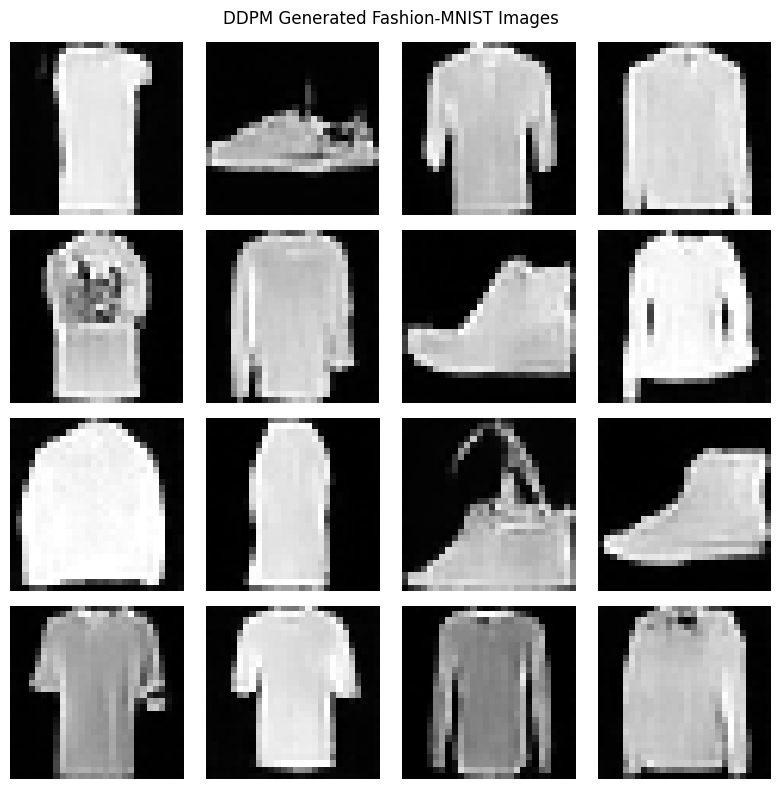

In [37]:
# Generate Image 16
torch.manual_seed(42)

if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(42)

ddpm_model.eval()

ddpm_generated_images, ddpm_trajectory = ddpm_sample(
    ddpm_model,
    num_samples=16
)

print("Generated Images Shape:",
      ddpm_generated_images.shape)

print("Trajectory Steps:",
      sorted(ddpm_trajectory.keys(), reverse=True))

fig, axes = plt.subplots(
    4, 4,
    figsize=(8, 8)
)

for i, ax in enumerate(axes.flat):

    image = ddpm_generated_images[i].cpu().squeeze().numpy()

    ax.imshow(
        np.clip(image, 0, 1),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.axis("off")

plt.suptitle("DDPM Generated Fashion-MNIST Images")
plt.tight_layout()
plt.show()


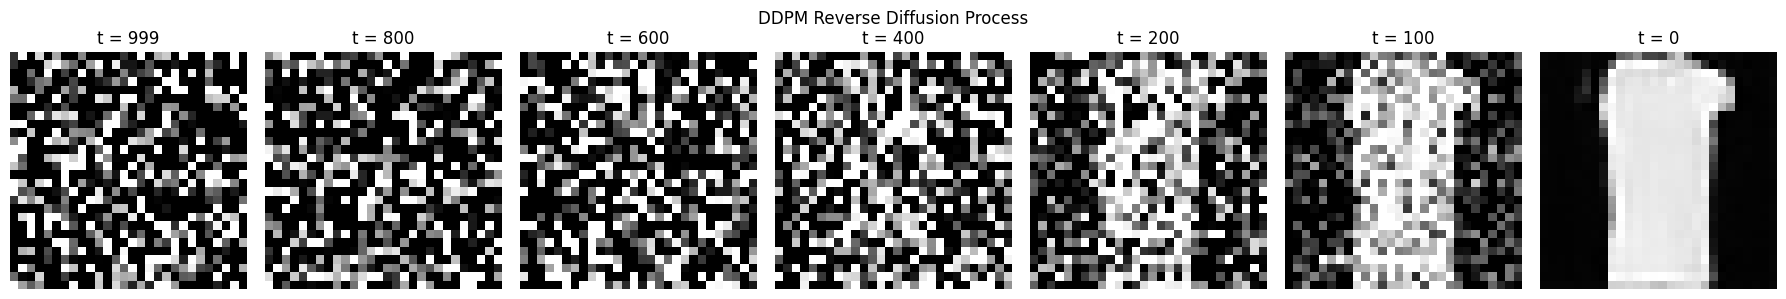

In [38]:
# DDPM reverse diffusion trajectory

trajectory_steps = sorted(ddpm_trajectory.keys(), reverse=True)

fig, axes = plt.subplots(1, len(trajectory_steps), figsize=(18, 3))

for i, step in enumerate(trajectory_steps):
    image = ddpm_trajectory[step]

    if isinstance(image, torch.Tensor):
        image = image.detach().cpu().squeeze().numpy()

    axes[i].imshow(image, cmap="gray", vmin=0, vmax=1)
    axes[i].set_title(f"t = {step}")
    axes[i].axis("off")

plt.suptitle("DDPM Reverse Diffusion Process")
plt.tight_layout()
plt.show()

In [39]:
# MLP classifier
class MLPClassifier(nn.Module):
    def __init__(self):
        super(MLPClassifier, self).__init__()

        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 10)

        self.relu = nn.ReLU()

    def extract_features(self, x):
        x = x.view(x.size(0), -1)
        x = self.relu(self.fc1(x))
        z = self.relu(self.fc2(x))
        return z

    def forward(self, x):
        z = self.extract_features(x)
        logits = self.fc3(z)
        return logits

In [40]:
# MLP -> Setup

mlp_classifier = MLPClassifier().to(DEVICE)

mlp_images, mlp_labels = next(iter(train_loader))
mlp_images = mlp_images.to(DEVICE)

with torch.no_grad():
    mlp_features = mlp_classifier.extract_features(mlp_images)
    mlp_logits = mlp_classifier(mlp_images)

print("MLP Classifier:")
print(mlp_classifier)

print("\nInput Shape:", mlp_images.shape)
print("Latent Feature Shape:", mlp_features.shape)
print("Output Logits Shape:", mlp_logits.shape)

MLP Classifier:
MLPClassifier(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
  (relu): ReLU()
)

Input Shape: torch.Size([128, 1, 28, 28])
Latent Feature Shape: torch.Size([128, 64])
Output Logits Shape: torch.Size([128, 10])


In [41]:
# MLP -> Training

mlp_criterion = nn.CrossEntropyLoss()
mlp_optimizer = torch.optim.Adam(
    mlp_classifier.parameters(),
    lr=LEARNING_RATE
)

mlp_train_losses = []
mlp_val_losses = []
mlp_train_accuracies = []
mlp_val_accuracies = []

best_mlp_val_accuracy = 0.0
best_mlp_state = None

for epoch in range(EPOCHS):
    start_time = time.time()

    mlp_classifier.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        mlp_optimizer.zero_grad()

        logits = mlp_classifier(images)
        loss = mlp_criterion(logits, labels)

        loss.backward()
        mlp_optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = torch.argmax(logits, dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_accuracy = train_correct / train_total

    mlp_classifier.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            logits = mlp_classifier(images)
            loss = mlp_criterion(logits, labels)

            val_loss += loss.item() * images.size(0)

            predictions = torch.argmax(logits, dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total

    mlp_train_losses.append(train_loss)
    mlp_val_losses.append(val_loss)
    mlp_train_accuracies.append(train_accuracy)
    mlp_val_accuracies.append(val_accuracy)

    if val_accuracy > best_mlp_val_accuracy:
        best_mlp_val_accuracy = val_accuracy
        best_mlp_state = {
            key: value.detach().cpu().clone()
            for key, value in mlp_classifier.state_dict().items()
        }

    elapsed = time.time() - start_time

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Time: {elapsed:.2f}s"
    )

mlp_classifier.load_state_dict(best_mlp_state)

print(f"\nBest Validation Accuracy: {best_mlp_val_accuracy:.4f}")

Epoch [1/20] | Train Loss: 0.6030 | Val Loss: 0.4402 | Train Acc: 0.7911 | Val Acc: 0.8443 | Time: 7.60s
Epoch [2/20] | Train Loss: 0.4108 | Val Loss: 0.3977 | Train Acc: 0.8530 | Val Acc: 0.8574 | Time: 7.62s
Epoch [3/20] | Train Loss: 0.3681 | Val Loss: 0.3863 | Train Acc: 0.8682 | Val Acc: 0.8573 | Time: 7.03s
Epoch [4/20] | Train Loss: 0.3361 | Val Loss: 0.3563 | Train Acc: 0.8783 | Val Acc: 0.8671 | Time: 7.70s
Epoch [5/20] | Train Loss: 0.3171 | Val Loss: 0.3416 | Train Acc: 0.8847 | Val Acc: 0.8731 | Time: 7.01s
Epoch [6/20] | Train Loss: 0.3013 | Val Loss: 0.3308 | Train Acc: 0.8893 | Val Acc: 0.8789 | Time: 7.59s
Epoch [7/20] | Train Loss: 0.2854 | Val Loss: 0.3234 | Train Acc: 0.8940 | Val Acc: 0.8829 | Time: 7.25s
Epoch [8/20] | Train Loss: 0.2745 | Val Loss: 0.3157 | Train Acc: 0.9000 | Val Acc: 0.8840 | Time: 7.59s
Epoch [9/20] | Train Loss: 0.2627 | Val Loss: 0.3214 | Train Acc: 0.9026 | Val Acc: 0.8809 | Time: 7.92s
Epoch [10/20] | Train Loss: 0.2520 | Val Loss: 0.3490 |

In [42]:
# MLP -> Test Evaluation

mlp_classifier.eval()

mlp_test_loss = 0.0
mlp_test_correct = 0
mlp_test_total = 0

mlp_test_predictions = []
mlp_test_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        logits = mlp_classifier(images)
        loss = mlp_criterion(logits, labels)

        predictions = torch.argmax(logits, dim=1)

        mlp_test_loss += loss.item() * images.size(0)
        mlp_test_correct += (predictions == labels).sum().item()
        mlp_test_total += labels.size(0)

        mlp_test_predictions.extend(predictions.cpu().numpy())
        mlp_test_labels.extend(labels.cpu().numpy())

mlp_test_loss /= mlp_test_total
mlp_test_accuracy = mlp_test_correct / mlp_test_total

print("MLP Classifier Test Results")
print(f"Test Loss: {mlp_test_loss:.4f}")
print(f"Test Accuracy: {mlp_test_accuracy:.4f}")
print(f"Test Accuracy: {mlp_test_accuracy * 100:.2f}%")

MLP Classifier Test Results
Test Loss: 0.3300
Test Accuracy: 0.8933
Test Accuracy: 89.33%


Classification Report:
              precision    recall  f1-score   support

 T-shirt/top     0.8234    0.8529    0.8379       700
     Trouser     0.9924    0.9848    0.9886       659
    Pullover     0.7987    0.8404    0.8190       708
       Dress     0.9226    0.8852    0.9035       714
        Coat     0.8358    0.7992    0.8171       707
      Sandal     0.9752    0.9545    0.9648       660
       Shirt     0.7145    0.7051    0.7098       685
     Sneaker     0.9584    0.9462    0.9522       706
         Bag     0.9681    0.9864    0.9772       738
  Ankle boot     0.9489    0.9765    0.9625       723

    accuracy                         0.8933      7000
   macro avg     0.8938    0.8931    0.8933      7000
weighted avg     0.8937    0.8933    0.8933      7000



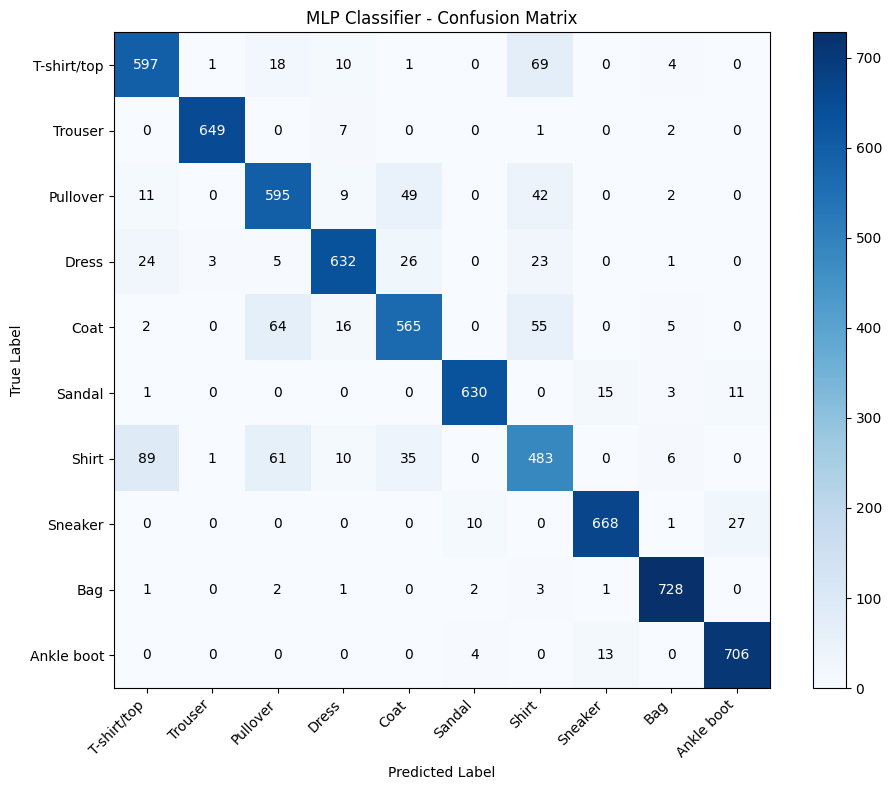

In [43]:
# MLP -> Confusion Matrix

print("Classification Report:")
print(
    classification_report(
        mlp_test_labels,
        mlp_test_predictions,
        target_names=class_names,
        digits=4
    )
)

cm = confusion_matrix(
    mlp_test_labels,
    mlp_test_predictions
)

plt.figure(figsize=(10, 8))
plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("MLP Classifier - Confusion Matrix")
plt.colorbar()

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=45,
    ha="right"
)
plt.yticks(np.arange(len(class_names)), class_names)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

threshold = cm.max() / 2

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, format(cm[i, j], "d"),
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black"
        )

plt.tight_layout()
plt.show()

Weight Shapes:
W1: torch.Size([256, 784])
W2: torch.Size([64, 256])
W3: torch.Size([10, 64])

Generated Images Shape: torch.Size([10, 1, 28, 28])


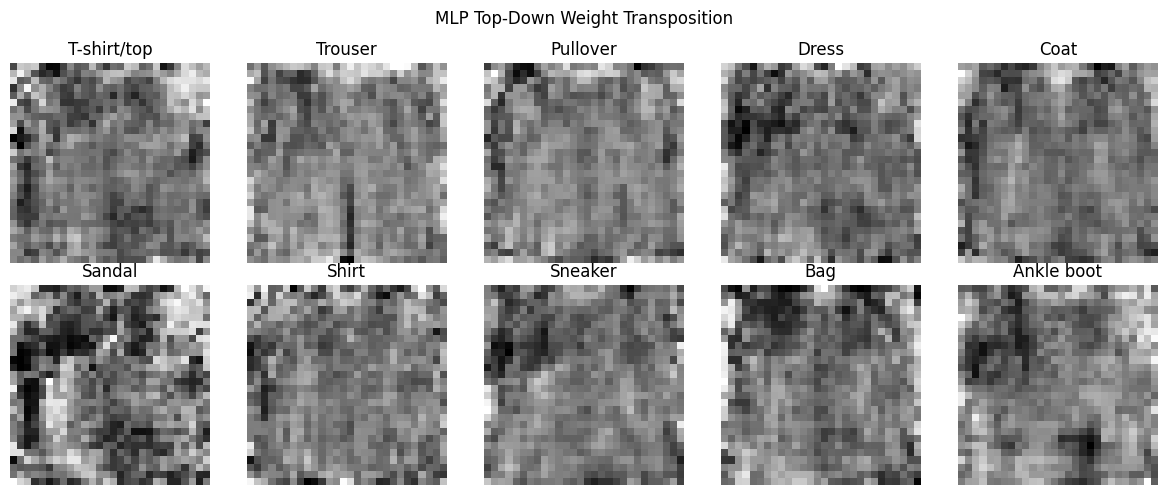

In [44]:
# Top-Down Weight Transposition

W1 = mlp_classifier.fc1.weight.detach().clone()
W2 = mlp_classifier.fc2.weight.detach().clone()
W3 = mlp_classifier.fc3.weight.detach().clone()

class_vectors = torch.eye(10, device=DEVICE)

mlp_classifier.eval()

with torch.no_grad():
    z_hat = F.relu(class_vectors @ W3)
    h1_hat = F.relu(z_hat @ W2)
    x_hat = torch.sigmoid(h1_hat @ W1)

    generated_class_images = x_hat.view(-1, 1, 28, 28)

print("Weight Shapes:")
print("W1:", W1.shape)
print("W2:", W2.shape)
print("W3:", W3.shape)

print("\nGenerated Images Shape:", generated_class_images.shape)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(generated_class_images[i, 0].cpu().numpy(), cmap="gray")
    ax.set_title(class_names[i])
    ax.axis("off")

plt.suptitle("MLP Top-Down Weight Transposition")
plt.tight_layout()
plt.show()

Original Images Shape: torch.Size([10, 1, 28, 28])
Latent Features Shape: torch.Size([10, 64])
Reconstructed Images Shape: torch.Size([10, 1, 28, 28])


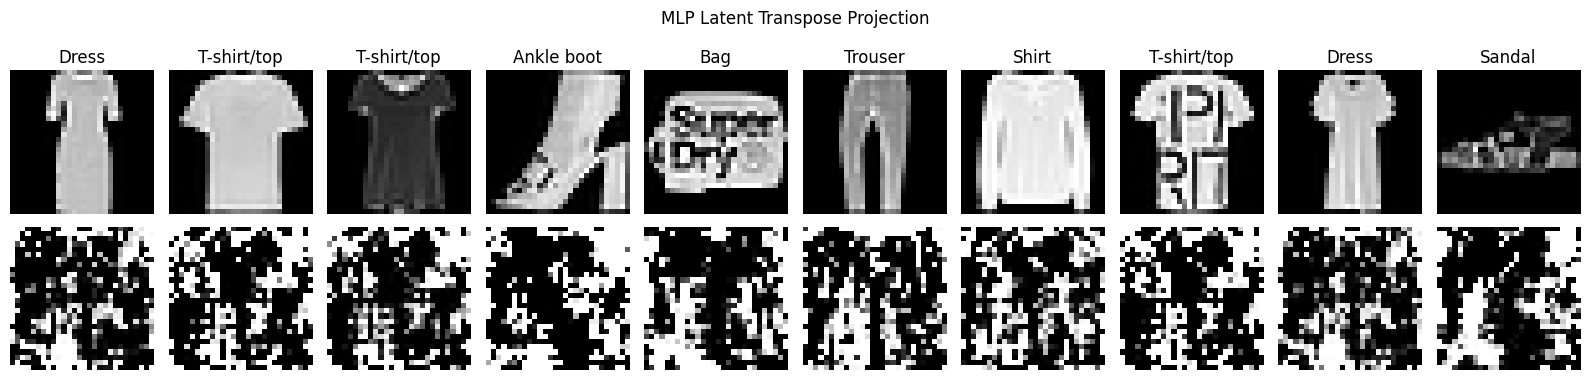

In [45]:
# Latent Transpose Projection

mlp_classifier.eval()

original_images, original_labels = next(iter(test_loader))

original_images = original_images[:10].to(DEVICE)
original_labels = original_labels[:10]

with torch.no_grad():

    z_mlp = mlp_classifier.extract_features(original_images)
    h1_reconstructed = F.relu(z_mlp @ W2)
    reconstructed_pixels = torch.sigmoid(h1_reconstructed @ W1)

    transpose_reconstructions = reconstructed_pixels.view(-1, 1, 28, 28)

print("Original Images Shape:", original_images.shape)
print("Latent Features Shape:", z_mlp.shape)
print("Reconstructed Images Shape:", transpose_reconstructions.shape)

fig, axes = plt.subplots(2, 10, figsize=(16, 4))

for i in range(10):
    axes[0, i].imshow(original_images[i, 0].cpu().numpy(), cmap="gray")
    axes[0, i].set_title(class_names[original_labels[i].item()])
    axes[0, i].axis("off")

    axes[1, i].imshow(
        transpose_reconstructions[i, 0].cpu().numpy(),
        cmap="gray"
    )
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=10)
axes[1, 0].set_ylabel("Transpose", fontsize=10)

plt.suptitle("MLP Latent Transpose Projection")
plt.tight_layout()
plt.show()

In [46]:
# Frozen Latent Decoding

for param in mlp_classifier.parameters():
    param.requires_grad = False

mlp_classifier.eval()

class FrozenLatentDecoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.decoder = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, z):
        reconstructed = self.decoder(z)
        return reconstructed.view(-1, 1, 28, 28)


mlp_decoder = FrozenLatentDecoder().to(DEVICE)

mlp_decoder_criterion = nn.MSELoss()

mlp_decoder_optimizer = torch.optim.Adam(
    mlp_decoder.parameters(),
    lr=LEARNING_RATE
)

mlp_decoder_train_losses = []
mlp_decoder_val_losses = []

best_mlp_decoder_val_loss = float("inf")
best_mlp_decoder_state = None

for epoch in range(EPOCHS):

    start_time = time.time()
    mlp_decoder.train()
    train_loss = 0.0
    train_total = 0

    for images, _ in train_loader:
        images = images.to(DEVICE)

        with torch.no_grad():
            z = mlp_classifier.extract_features(images)

        mlp_decoder_optimizer.zero_grad()

        reconstructed = mlp_decoder(z)
        loss = mlp_decoder_criterion(reconstructed, images)

        loss.backward()
        mlp_decoder_optimizer.step()

        train_loss += loss.item() * images.size(0)
        train_total += images.size(0)

    train_loss /= train_total

    mlp_decoder.eval()
    val_loss = 0.0
    val_total = 0

    with torch.no_grad():
        for images, _ in val_loader:
            images = images.to(DEVICE)

            z = mlp_classifier.extract_features(images)
            reconstructed = mlp_decoder(z)

            loss = mlp_decoder_criterion(reconstructed, images)

            val_loss += loss.item() * images.size(0)
            val_total += images.size(0)

    val_loss /= val_total

    mlp_decoder_train_losses.append(train_loss)
    mlp_decoder_val_losses.append(val_loss)

    if val_loss < best_mlp_decoder_val_loss:
        best_mlp_decoder_val_loss = val_loss
        best_mlp_decoder_state = {
            key: value.detach().cpu().clone()
            for key, value in mlp_decoder.state_dict().items()
        }

    elapsed = time.time() - start_time

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f} | "
        f"Time: {elapsed:.2f}s"
    )

mlp_decoder.load_state_dict(best_mlp_decoder_state)

print(f"\nBest Decoder Validation Loss: {best_mlp_decoder_val_loss:.6f}")
print("\nMLP Classifier Frozen:", all(
    not param.requires_grad
    for param in mlp_classifier.parameters()
))

Epoch [1/20] | Train Loss: 0.036745 | Val Loss: 0.027347 | Time: 7.71s
Epoch [2/20] | Train Loss: 0.025180 | Val Loss: 0.023977 | Time: 6.79s
Epoch [3/20] | Train Loss: 0.022895 | Val Loss: 0.022487 | Time: 7.76s
Epoch [4/20] | Train Loss: 0.021659 | Val Loss: 0.021540 | Time: 7.19s
Epoch [5/20] | Train Loss: 0.020887 | Val Loss: 0.020857 | Time: 7.73s
Epoch [6/20] | Train Loss: 0.020306 | Val Loss: 0.020383 | Time: 7.83s
Epoch [7/20] | Train Loss: 0.019841 | Val Loss: 0.020219 | Time: 7.05s
Epoch [8/20] | Train Loss: 0.019520 | Val Loss: 0.019754 | Time: 7.85s
Epoch [9/20] | Train Loss: 0.019209 | Val Loss: 0.019523 | Time: 6.97s
Epoch [10/20] | Train Loss: 0.018949 | Val Loss: 0.019383 | Time: 7.71s
Epoch [11/20] | Train Loss: 0.018759 | Val Loss: 0.019041 | Time: 7.25s
Epoch [12/20] | Train Loss: 0.018553 | Val Loss: 0.018929 | Time: 7.34s
Epoch [13/20] | Train Loss: 0.018372 | Val Loss: 0.018752 | Time: 7.80s
Epoch [14/20] | Train Loss: 0.018243 | Val Loss: 0.018823 | Time: 6.92s
E

In [47]:
# Test Set Evaluation

mlp_decoder.eval()
vanilla_ae.eval()

mlp_squared_error = 0
ae_squared_error = 0
total_pixels = 0

mlp_psnr_values = []
mlp_ssim_values = []

ae_psnr_values = []
ae_ssim_values = []

with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(DEVICE)

        z_mlp = mlp_classifier.extract_features(images)
        mlp_reconstructed = mlp_decoder(z_mlp)

        ae_reconstructed = vanilla_ae(images)

        mlp_error = (mlp_reconstructed - images) ** 2
        ae_error = (ae_reconstructed - images) ** 2

        mlp_squared_error += mlp_error.sum().item()
        ae_squared_error += ae_error.sum().item()

        total_pixels += images.numel()

        mlp_mse_per_image = mlp_error.mean(dim=(1, 2, 3))
        ae_mse_per_image = ae_error.mean(dim=(1, 2, 3))

        mlp_psnr = 10 * torch.log10(
            1.0 / mlp_mse_per_image.clamp_min(1e-10)
        )

        ae_psnr = 10 * torch.log10(
            1.0 / ae_mse_per_image.clamp_min(1e-10)
        )

        mlp_psnr_values.extend(mlp_psnr.cpu().numpy())
        ae_psnr_values.extend(ae_psnr.cpu().numpy())

        original_np = images.cpu().numpy()
        mlp_np = mlp_reconstructed.cpu().numpy()
        ae_np = ae_reconstructed.cpu().numpy()

        for i in range(len(images)):
            mlp_score = structural_similarity(
                original_np[i, 0],
                mlp_np[i, 0],
                data_range=1.0
            )

            ae_score = structural_similarity(
                original_np[i, 0],
                ae_np[i, 0],
                data_range=1.0
            )

            mlp_ssim_values.append(mlp_score)
            ae_ssim_values.append(ae_score)


# metrics
mlp_decoder_test_mse = mlp_squared_error / total_pixels
mlp_decoder_test_psnr = np.mean(mlp_psnr_values)
mlp_decoder_test_ssim = np.mean(mlp_ssim_values)

ae_test_mse = ae_squared_error / total_pixels
ae_test_psnr = np.mean(ae_psnr_values)
ae_test_ssim = np.mean(ae_ssim_values)


print("FROZEN LATENT DECODER vs VANILLA AE")

print("\nMLP Frozen Latent Decoder:")
print(f"Test MSE  : {mlp_decoder_test_mse:.6f}")
print(f"Test PSNR : {mlp_decoder_test_psnr:.4f}")
print(f"Test SSIM : {mlp_decoder_test_ssim:.6f}")

print("\nVanilla Autoencoder:")
print(f"Test MSE  : {ae_test_mse:.6f}")
print(f"Test PSNR : {ae_test_psnr:.4f}")
print(f"Test SSIM : {ae_test_ssim:.6f}")

FROZEN LATENT DECODER vs VANILLA AE

MLP Frozen Latent Decoder:
Test MSE  : 0.018117
Test PSNR : 18.1858
Test SSIM : 0.650995

Vanilla Autoencoder:
Test MSE  : 0.007096
Test PSNR : 22.5605
Test SSIM : 0.815026


Test Latent Features Shape: torch.Size([7000, 64])
Latent Mean Shape: torch.Size([64])
Latent Std Shape: torch.Size([64])
Random Latents Shape: torch.Size([16, 64])
Generated Images Shape: torch.Size([16, 1, 28, 28])


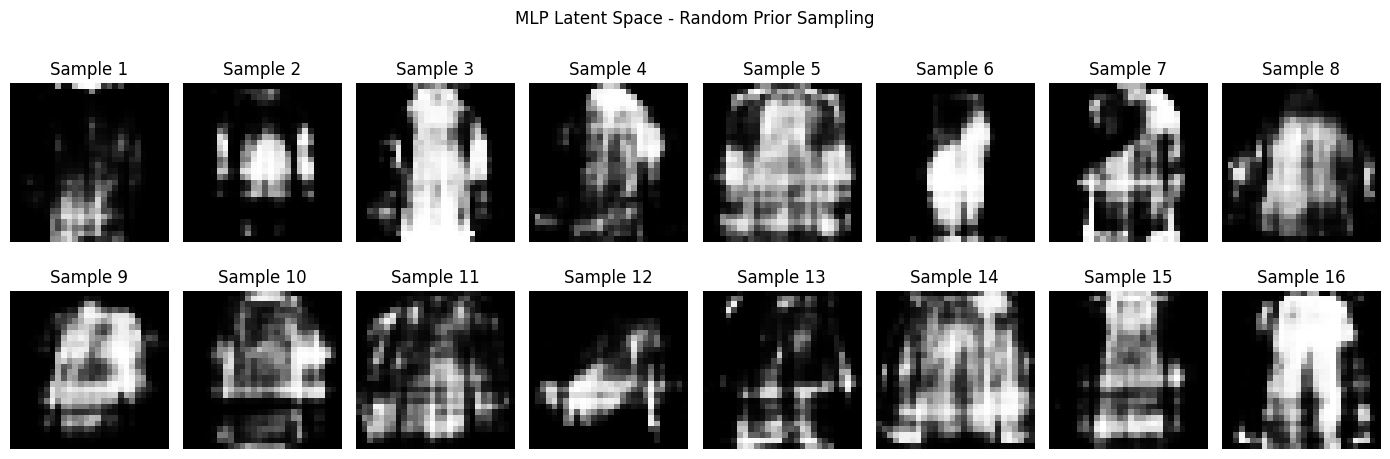

In [48]:
# Generative Sampling on MLP Latent Space

mlp_classifier.eval()
mlp_decoder.eval()

all_test_latents = []

with torch.no_grad():
    for images, _ in test_loader:
        images = images.to(DEVICE)

        z = mlp_classifier.extract_features(images)
        all_test_latents.append(z)

all_test_latents = torch.cat(all_test_latents, dim=0)

latent_mean = all_test_latents.mean(dim=0)
latent_std = all_test_latents.std(dim=0, unbiased=False)

num_samples = 16

random_latents = (
    latent_mean.unsqueeze(0)
    + torch.randn(num_samples, 64, device=DEVICE)
    * latent_std.unsqueeze(0)
)

with torch.no_grad():
    generated_mlp_images = mlp_decoder(random_latents)

print("Test Latent Features Shape:", all_test_latents.shape)
print("Latent Mean Shape:", latent_mean.shape)
print("Latent Std Shape:", latent_std.shape)
print("Random Latents Shape:", random_latents.shape)
print("Generated Images Shape:", generated_mlp_images.shape)

fig, axes = plt.subplots(2, 8, figsize=(14, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        generated_mlp_images[i, 0].cpu().numpy(),
        cmap="gray"
    )
    ax.set_title(f"Sample {i+1}")
    ax.axis("off")

plt.suptitle("MLP Latent Space - Random Prior Sampling")
plt.tight_layout()
plt.show()

GAN Endpoint Confidence:
Vanilla GAN - Trouser: 1.0000
Vanilla GAN - Bag: 1.0000
DCGAN - Trouser: 1.0000
DCGAN - Bag: 1.0000


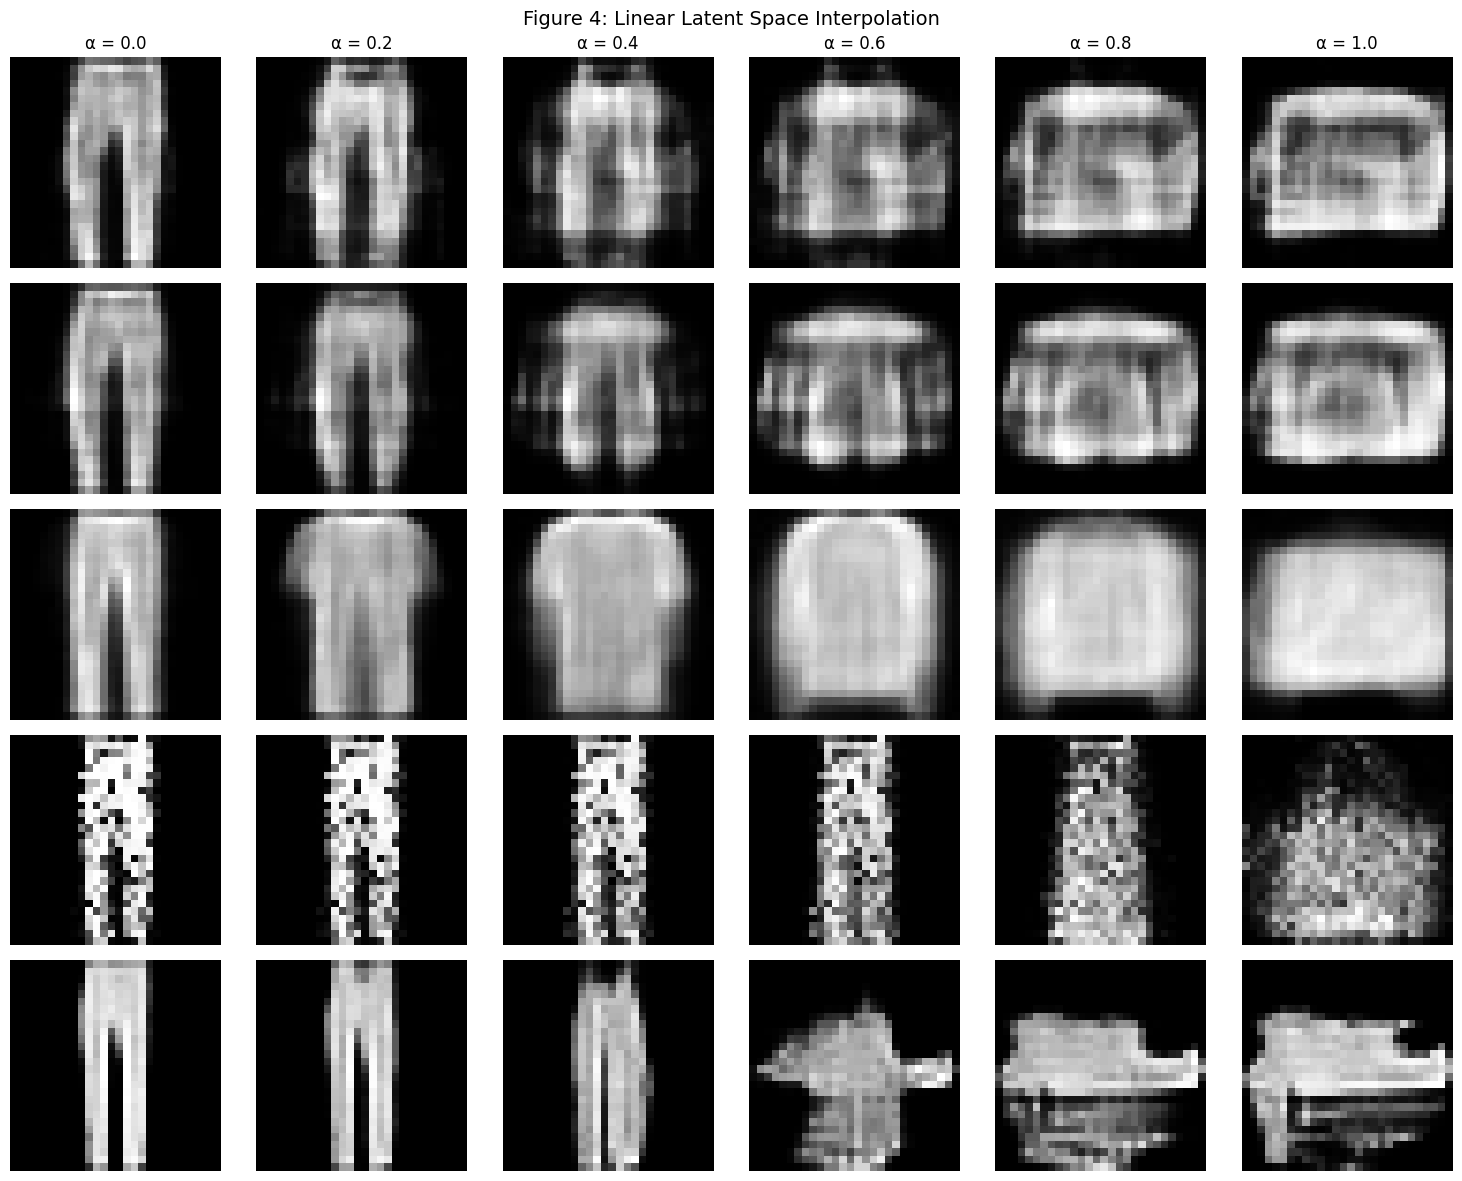

Interpolation complete


In [49]:
# Linear Latent Space Interpolation

vanilla_ae.eval()
sparse_ae.eval()
vae.eval()
generator.eval()
dc_generator.eval()
mlp_classifier.eval()

class_a = 1
class_b = 8

selected_images = {}

with torch.no_grad():

    for images, labels in test_loader:

        for target_class in [class_a, class_b]:

            if target_class not in selected_images:

                indices = (labels == target_class).nonzero(
                    as_tuple=True
                )[0]

                if len(indices) > 0:

                    selected_images[target_class] = (
                        images[indices[0]:indices[0]+1].to(DEVICE)
                    )

        if len(selected_images) == 2:
            break


image_a = selected_images[class_a]
image_b = selected_images[class_b]


with torch.no_grad():

    # Vanilla AE
    ae_z_a = vanilla_ae.encoder(image_a)
    ae_z_b = vanilla_ae.encoder(image_b)

    # Sparse AE
    sparse_z_a = sparse_ae.encoder(image_a)
    sparse_z_b = sparse_ae.encoder(image_b)

    # VAE
    vae_hidden_a = vae.encoder(image_a)
    vae_hidden_b = vae.encoder(image_b)

    vae_z_a = vae.fc_mu(vae_hidden_a)
    vae_z_b = vae.fc_mu(vae_hidden_b)



def find_class_latent(
    gen_model,
    target_class,
    num_candidates=1024,
    chunk_size=64
):

    best_score = -1.0
    best_latent = None

    with torch.inference_mode():

        for start in range(0, num_candidates, chunk_size):

            batch_size = min(
                chunk_size,
                num_candidates - start
            )

            z_candidates = torch.randn(
                batch_size,
                100,
                device=DEVICE
            )

            generated = gen_model(z_candidates)

            probabilities = F.softmax(
                mlp_classifier(generated),
                dim=1
            )

            scores = probabilities[:, target_class]

            best_index = torch.argmax(scores)

            current_score = scores[best_index].item()

            if current_score > best_score:

                best_score = current_score

                best_latent = z_candidates[
                    best_index:best_index+1
                ].clone()

    return best_latent, best_score

gan_z_a, gan_score_a = find_class_latent(
    generator, class_a
)

gan_z_b, gan_score_b = find_class_latent(
    generator, class_b
)

dcgan_z_a, dcgan_score_a = find_class_latent(
    dc_generator, class_a
)

dcgan_z_b, dcgan_score_b = find_class_latent(
    dc_generator, class_b
)


print("GAN Endpoint Confidence:")

print(f"Vanilla GAN - Trouser: {gan_score_a:.4f}")
print(f"Vanilla GAN - Bag: {gan_score_b:.4f}")

print(f"DCGAN - Trouser: {dcgan_score_a:.4f}")
print(f"DCGAN - Bag: {dcgan_score_b:.4f}")


latent_pairs = {

    "Vanilla AE": (ae_z_a, ae_z_b),

    "Sparse AE": (sparse_z_a, sparse_z_b),

    "VAE": (vae_z_a, vae_z_b),

    "Vanilla GAN": (gan_z_a, gan_z_b),

    "DCGAN": (dcgan_z_a, dcgan_z_b)

}


interp_alphas = torch.linspace(
    0,
    1,
    6,
    device=DEVICE
)


interpolation_results = {}

with torch.no_grad():

    for model_name, (z_a, z_b) in latent_pairs.items():

        interpolated_images = []

        for alpha in interp_alphas:

            z_interpolated = (
                (1 - alpha) * z_a
                + alpha * z_b
            )

            if model_name == "Vanilla AE":

                output = vanilla_ae.decoder(
                    z_interpolated
                )

            elif model_name == "Sparse AE":

                output = sparse_ae.decoder(
                    z_interpolated
                )

            elif model_name == "VAE":

                output = vae.decoder(
                    z_interpolated
                )

            elif model_name == "Vanilla GAN":

                output = generator(
                    z_interpolated
                )

            else:

                output = dc_generator(
                    z_interpolated
                )

            if output.dim() == 2:

                output = output.view(
                    -1, 1, 28, 28
                )

            interpolated_images.append(
                output[0, 0].cpu().numpy()
            )

        interpolation_results[model_name] = (
            interpolated_images
        )


fig, axes = plt.subplots(
    5,
    6,
    figsize=(15, 12)
)

for row, (model_name, images) in enumerate(
    interpolation_results.items()
):

    for col, image in enumerate(images):

        axes[row, col].imshow(
            image,
            cmap="gray"
        )

        axes[row, col].axis("off")

        if row == 0:

            axes[row, col].set_title(
                f"α = {interp_alphas[col].item():.1f}"
            )

    axes[row, 0].set_ylabel(
        model_name,
        rotation=0,
        labelpad=65,
        fontsize=10,
        va="center"
    )


plt.suptitle(
    "Figure 4: Linear Latent Space Interpolation",
    fontsize=14
)

plt.tight_layout()
plt.show()


del selected_images, image_a, image_b

del ae_z_a, ae_z_b
del sparse_z_a, sparse_z_b

del vae_hidden_a, vae_hidden_b
del vae_z_a, vae_z_b

del gan_z_a, gan_z_b
del dcgan_z_a, dcgan_z_b

del latent_pairs, interp_alphas

gc.collect()

if DEVICE.type == "cuda":

    torch.cuda.synchronize()
    torch.cuda.empty_cache()


print("Interpolation complete")

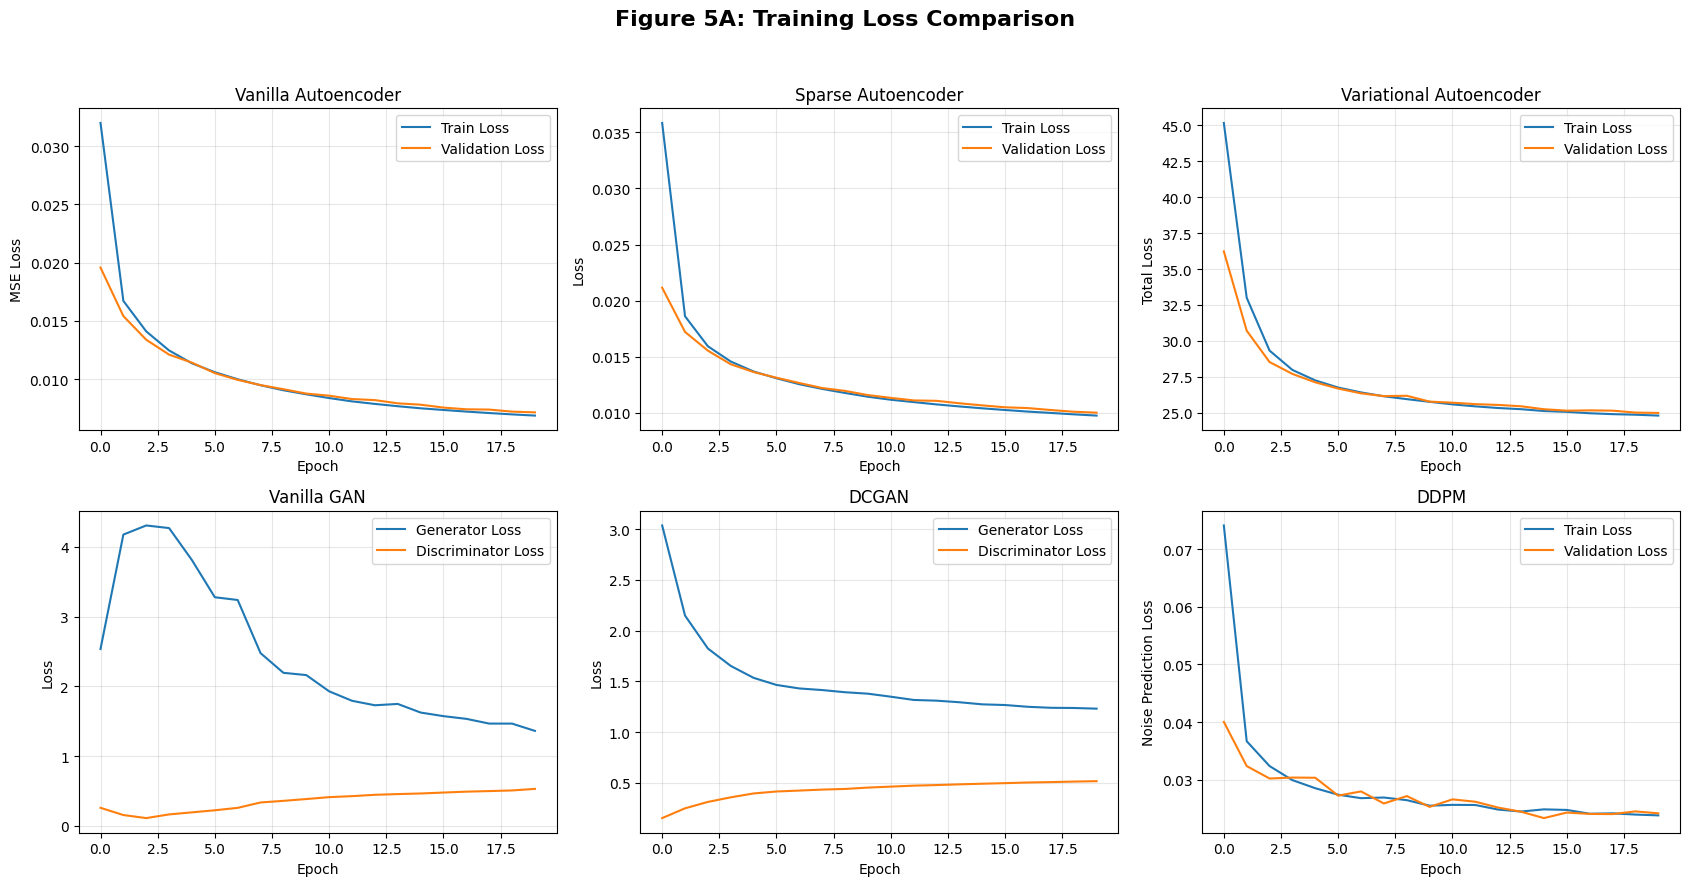

Training Loss Curves completed!
Saved to: outputs/figure_5_training_losses.png


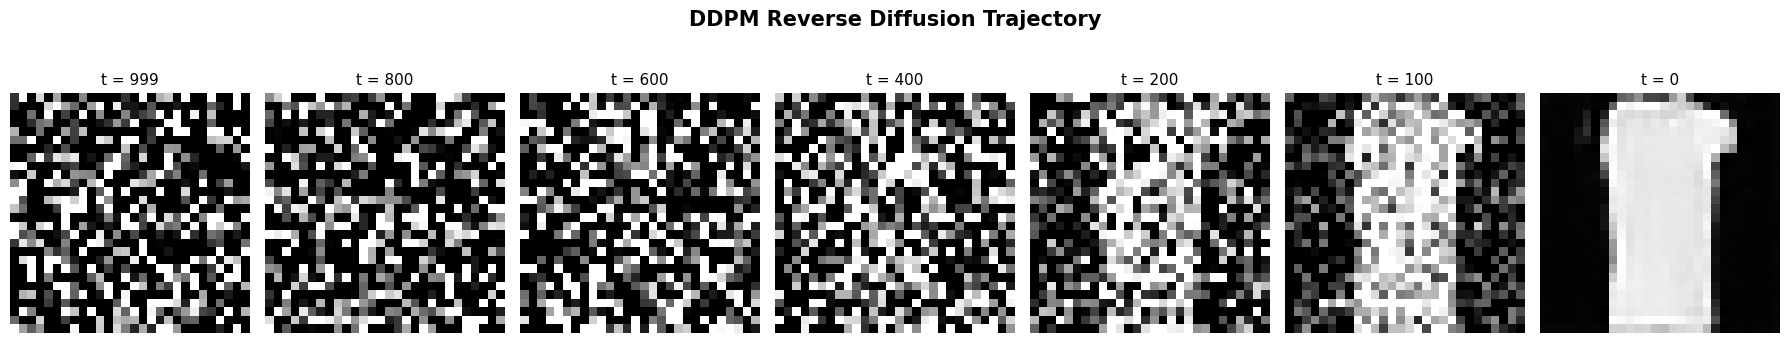

DDPM Reverse Diffusion Trajectory completed!
Saved to: outputs/figure_5_ddpm_trajectory.png

FIGURE 5 COMPLETED
Saved files:
1. outputs/figure_5_training_losses.png
2. outputs/figure_5_ddpm_trajectory.png


In [50]:
# F5
# TRAINING LOSS CURVES & DDPM TRAJECTORY

os.makedirs("outputs", exist_ok=True)

fig, axes = plt.subplots(2, 3, figsize=(17, 9))

# 1. Vanilla Autoencoder
axes[0, 0].plot(train_losses, label="Train Loss")
axes[0, 0].plot(val_losses, label="Validation Loss")
axes[0, 0].set_title("Vanilla Autoencoder")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("MSE Loss")
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# 2. Sparse Autoencoder
axes[0, 1].plot(
    sparse_train_losses,
    label="Train Loss"
)
axes[0, 1].plot(
    sparse_val_losses,
    label="Validation Loss"
)
axes[0, 1].set_title("Sparse Autoencoder")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# 3. Variational Autoencoder
axes[0, 2].plot(
    vae_train_losses,
    label="Train Loss"
)
axes[0, 2].plot(
    vae_val_losses,
    label="Validation Loss"
)
axes[0, 2].set_title("Variational Autoencoder")
axes[0, 2].set_xlabel("Epoch")
axes[0, 2].set_ylabel("Total Loss")
axes[0, 2].legend()
axes[0, 2].grid(alpha=0.3)

# 4. Vanilla GAN
axes[1, 0].plot(
    gan_g_losses,
    label="Generator Loss"
)
axes[1, 0].plot(
    gan_d_losses,
    label="Discriminator Loss"
)
axes[1, 0].set_title("Vanilla GAN")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Loss")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# 5. DCGAN
axes[1, 1].plot(
    dc_g_losses,
    label="Generator Loss"
)
axes[1, 1].plot(
    dc_d_losses,
    label="Discriminator Loss"
)
axes[1, 1].set_title("DCGAN")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Loss")
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3)

# 6. DDPM
axes[1, 2].plot(
    ddpm_train_losses,
    label="Train Loss"
)
axes[1, 2].plot(
    ddpm_val_losses,
    label="Validation Loss"
)
axes[1, 2].set_title("DDPM")
axes[1, 2].set_xlabel("Epoch")
axes[1, 2].set_ylabel("Noise Prediction Loss")
axes[1, 2].legend()
axes[1, 2].grid(alpha=0.3)

fig.suptitle(
    "Figure 5A: Training Loss Comparison",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout(rect=[0, 0, 1, 0.95])

loss_save_path = "outputs/figure_5_training_losses.png"

fig.savefig(
    loss_save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Training Loss Curves completed!")
print("Saved to:", loss_save_path)


trajectory_steps = sorted(
    ddpm_trajectory.keys(),
    reverse=True
)

fig, axes = plt.subplots(
    1,
    len(trajectory_steps),
    figsize=(18, 3.5)
)

for i, step in enumerate(trajectory_steps):

    image = ddpm_trajectory[step]

    if isinstance(image, torch.Tensor):
        image = image.detach().cpu().squeeze().numpy()
    else:
        image = np.asarray(image).squeeze()

    axes[i].imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[i].set_title(
        f"t = {step}",
        fontsize=11
    )

    axes[i].axis("off")

fig.suptitle(
    "DDPM Reverse Diffusion Trajectory",
    fontsize=15,
    fontweight="bold"
)

fig.tight_layout(rect=[0, 0, 1, 0.90])

trajectory_save_path = (
    "outputs/figure_5_ddpm_trajectory.png"
)

fig.savefig(
    trajectory_save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("DDPM Reverse Diffusion Trajectory completed!")
print("Saved to:", trajectory_save_path)


print("\nFIGURE 5 COMPLETED")
print("Saved files:")
print("1.", loss_save_path)
print("2.", trajectory_save_path)


In [51]:
# Training Time and Inference Latency Benchmark

BENCHMARK_BATCH_SIZE = 64
DDPM_CHUNK_SIZE = 16
WARMUP = 1
REPEATS = 3

gc.collect()
if DEVICE.type == "cuda":
    torch.cuda.synchronize()
    torch.cuda.empty_cache()

training_times = {
    "Vanilla AE": float(np.mean(epoch_times)),
    "Sparse AE": float(np.mean(sparse_epoch_times)),
    "VAE": float(np.mean(vae_epoch_times)),
    "Vanilla GAN": float(np.mean(gan_epoch_times)),
    "DCGAN": float(np.mean(dc_epoch_times)),
    "DDPM": float(np.mean(ddpm_epoch_times)),
}

benchmark_images = torch.randn(
    BENCHMARK_BATCH_SIZE, 1, 28, 28, device=DEVICE
)
vae_noise = torch.randn(
    BENCHMARK_BATCH_SIZE, LATENT_DIM, device=DEVICE
)
gan_noise = torch.randn(
    BENCHMARK_BATCH_SIZE, GAN_LATENT_DIM, device=DEVICE
)
dcgan_noise = torch.randn(
    BENCHMARK_BATCH_SIZE, DCGAN_LATENT_DIM, device=DEVICE
)

for model in [vanilla_ae, sparse_ae, vae, generator, dc_generator, ddpm_model]:
    model.eval()


def ddpm_generate_batch64():

    generated_chunks = []

    for start in range(0, BENCHMARK_BATCH_SIZE, DDPM_CHUNK_SIZE):
        current_batch = min(
            DDPM_CHUNK_SIZE,
            BENCHMARK_BATCH_SIZE - start
        )
        x = torch.randn(current_batch, 1, 28, 28, device=DEVICE)

        for step in reversed(range(TIMESTEPS)):
            t = torch.full(
                (current_batch,), step,
                device=DEVICE, dtype=torch.long
            )
            x = p_sample(ddpm_model, x, t)

        generated_chunks.append(x)

    return torch.cat(generated_chunks, dim=0)


def assert_finite_output(output):

    if isinstance(output, torch.Tensor):
        if not torch.isfinite(output).all().item():
            raise FloatingPointError("Model output contains NaN or Inf")
    elif isinstance(output, (tuple, list)):
        for item in output:
            assert_finite_output(item)
    else:
        raise TypeError(f"Unsupported model output type: {type(output)}")


def benchmark_latency(model_function):
    timings_ms = []

    with torch.inference_mode():

        for _ in range(WARMUP):
            warmup_output = model_function()
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            assert_finite_output(warmup_output)
            del warmup_output


        for _ in range(REPEATS):
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()

            start_time = time.perf_counter()
            output = model_function()

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()

            timings_ms.append((time.perf_counter() - start_time) * 1000)
            assert_finite_output(output)
            del output

    return {
        "median": float(np.median(timings_ms)),
        "mean": float(np.mean(timings_ms)),
        "std": float(np.std(timings_ms, ddof=1)),
        "runs": timings_ms,
    }


benchmark_functions = {
    "Vanilla AE": lambda: vanilla_ae(benchmark_images),
    "Sparse AE": lambda: sparse_ae(benchmark_images),
    "VAE": lambda: vae.decoder(vae_noise),
    "Vanilla GAN": lambda: generator(gan_noise),
    "DCGAN": lambda: dc_generator(dcgan_noise),
    "DDPM": ddpm_generate_batch64,
}

print("FINAL INFERENCE BENCHMARK")
print("Device:", DEVICE)
print("Batch size:", BENCHMARK_BATCH_SIZE)
print("DDPM chunk size:", DDPM_CHUNK_SIZE)
print("Warm-up runs:", WARMUP)
print("Measurement runs:", REPEATS)
print("DDPM timesteps:", TIMESTEPS)

benchmark_stats = {}
for model_name, model_function in benchmark_functions.items():
    print(f"\nBenchmarking {model_name}...")
    stats = benchmark_latency(model_function)
    benchmark_stats[model_name] = stats
    print("Runs (ms):", [round(x, 3) for x in stats["runs"]])
    print("Median (ms):", round(stats["median"], 3))
    print("Std (ms):", round(stats["std"], 3))

benchmark_results = pd.DataFrame({
    "Model": list(training_times.keys()),
    "Average Training Time / Epoch (s)": [training_times[name] for name in training_times],
    "Median Inference Latency / Batch 64 (ms)": [benchmark_stats[name]["median"] for name in training_times],
    "Latency Std (ms)": [benchmark_stats[name]["std"] for name in training_times],
})

print("\nFINAL BENCHMARK RESULTS")
display(benchmark_results.round(3))

OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
benchmark_results.to_csv(
    os.path.join(OUTPUT_DIR, "benchmark_results_final.csv"), index=False
)
pd.DataFrame({
    name: benchmark_stats[name]["runs"] for name in training_times
}).to_csv(
    os.path.join(OUTPUT_DIR, "benchmark_raw_measurements.csv"), index=False
)

print("\nBenchmark files saved in:", os.path.abspath(OUTPUT_DIR))
print("Benchmark completed successfully!")


FINAL INFERENCE BENCHMARK
Device: cuda
Batch size: 64
DDPM chunk size: 16
Warm-up runs: 1
Measurement runs: 3
DDPM timesteps: 1000

Benchmarking Vanilla AE...
Runs (ms): [0.5, 0.461, 0.363]
Median (ms): 0.461
Std (ms): 0.071

Benchmarking Sparse AE...
Runs (ms): [0.405, 0.388, 0.571]
Median (ms): 0.405
Std (ms): 0.101

Benchmarking VAE...
Runs (ms): [0.271, 0.284, 0.225]
Median (ms): 0.271
Std (ms): 0.031

Benchmarking Vanilla GAN...
Runs (ms): [0.296, 0.362, 0.962]
Median (ms): 0.362
Std (ms): 0.367

Benchmarking DCGAN...
Runs (ms): [2.613, 2.595, 2.632]
Median (ms): 2.613
Std (ms): 0.018

Benchmarking DDPM...
Runs (ms): [15138.759, 15035.699, 14824.963]
Median (ms): 15035.699
Std (ms): 159.948

FINAL BENCHMARK RESULTS


,Model,Average Training Time / Epoch (s),Median Inference Latency / Batch 64 (ms),Latency Std (ms)
0,Vanilla AE,8.436,0.461,0.071
1,Sparse AE,7.699,0.405,0.101
2,VAE,8.131,0.271,0.031
3,Vanilla GAN,8.230,0.362,0.367
4,DCGAN,13.867,2.613,0.018
5,DDPM,24.924,15035.699,159.948



Benchmark files saved in: /content/outputs
Benchmark completed successfully!


In [52]:
# FID Evaluation


FID_SAMPLES = 1000
FID_BATCH_SIZE = 32
DDPM_FID_BATCH_SIZE = 8

torch.manual_seed(SEED + 123)
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED + 123)

def prepare_fid_images(images):
    images = images.detach().clamp(0, 1)
    images = (images * 255).round().to(torch.uint8)
    return images.repeat(1, 3, 1, 1)

fid_metric = FrechetInceptionDistance(
    feature=2048,
    normalize=False,
    reset_real_features=False
).to(DEVICE)

fid_metric.set_dtype(torch.float64)

print("Extracting real Test Set features...")

real_count = 0

with torch.inference_mode():
    for images, _ in test_loader:
        remaining = FID_SAMPLES - real_count
        if remaining <= 0:
            break

        images = images[:remaining].to(DEVICE)
        fid_metric.update(
            prepare_fid_images(images),
            real=True
        )
        real_count += images.size(0)

assert real_count == FID_SAMPLES

print(f"Real features ready: {real_count} images")


vae.eval()
generator.eval()
dc_generator.eval()
ddpm_model.eval()

@torch.inference_mode()
def fid_sample_vae(n):
    z = torch.randn(n, LATENT_DIM, device=DEVICE)
    return vae.decoder(z).view(n, 1, 28, 28)

@torch.inference_mode()
def fid_sample_gan(n):
    z = torch.randn(n, GAN_LATENT_DIM, device=DEVICE)
    return generator(z)

@torch.inference_mode()
def fid_sample_dcgan(n):
    z = torch.randn(n, DCGAN_LATENT_DIM, device=DEVICE)
    return dc_generator(z)

@torch.inference_mode()
def fid_sample_ddpm(n):
    images, _ = ddpm_sample(ddpm_model, num_samples=n)
    return images

models_for_fid = {
    "VAE": (fid_sample_vae, FID_BATCH_SIZE),
    "Vanilla GAN": (fid_sample_gan, FID_BATCH_SIZE),
    "DCGAN": (fid_sample_dcgan, FID_BATCH_SIZE),
    "DDPM": (fid_sample_ddpm, DDPM_FID_BATCH_SIZE)
}


fid_results = []

for model_name, (sample_function, batch_size) in models_for_fid.items():

    fid_metric.reset()

    print(f"\nEvaluating {model_name}...")

    generated_count = 0

    with torch.inference_mode():
        while generated_count < FID_SAMPLES:

            n = min(
                batch_size,
                FID_SAMPLES - generated_count
            )

            fake_images = sample_function(n)

            assert torch.isfinite(fake_images).all(), (
                f"{model_name}: NaN or Inf detected"
            )

            fid_metric.update(
                prepare_fid_images(fake_images),
                real=False
            )

            generated_count += n

            if (
                generated_count % 100 < n
                or generated_count == FID_SAMPLES
            ):
                print(
                    f"  {generated_count}/{FID_SAMPLES} images"
                )

            del fake_images

    score = float(fid_metric.compute().item())

    if not np.isfinite(score):
        raise ValueError(f"Invalid FID for {model_name}")

    fid_results.append({
        "Model": model_name,
        "FID": score,
        "Real Samples": FID_SAMPLES,
        "Generated Samples": FID_SAMPLES,
        "Feature Dimension": 2048
    })

    print(f"{model_name} FID: {score:.4f}")

fid_df = pd.DataFrame(fid_results)

print("\nFID Results")
display(fid_df.round(4))

os.makedirs("outputs", exist_ok=True)
fid_df.to_csv("outputs/fid_scores.csv", index=False)

print("\nFID evaluation completed!")
print("Saved to outputs/fid_scores.csv")


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 118MB/s]


Extracting real Test Set features...
Real features ready: 1000 images

Evaluating VAE...
  128/1000 images
  224/1000 images
  320/1000 images
  416/1000 images
  512/1000 images
  608/1000 images
  704/1000 images
  800/1000 images
  928/1000 images
  1000/1000 images
VAE FID: 108.6526

Evaluating Vanilla GAN...
  128/1000 images
  224/1000 images
  320/1000 images
  416/1000 images
  512/1000 images
  608/1000 images
  704/1000 images
  800/1000 images
  928/1000 images
  1000/1000 images
Vanilla GAN FID: 183.9383

Evaluating DCGAN...
  128/1000 images
  224/1000 images
  320/1000 images
  416/1000 images
  512/1000 images
  608/1000 images
  704/1000 images
  800/1000 images
  928/1000 images
  1000/1000 images
DCGAN FID: 47.3670

Evaluating DDPM...
  104/1000 images
  200/1000 images
  304/1000 images
  400/1000 images
  504/1000 images
  600/1000 images
  704/1000 images
  800/1000 images
  904/1000 images
  1000/1000 images
DDPM FID: 71.3775

FID Results


,Model,FID,Real Samples,Generated Samples,Feature Dimension
0,VAE,108.6526,1000,1000,2048
1,Vanilla GAN,183.9383,1000,1000,2048
2,DCGAN,47.3670,1000,1000,2048
3,DDPM,71.3775,1000,1000,2048



FID evaluation completed!
Saved to outputs/fid_scores.csv


In [53]:
# Numerical Proof of Weight Non-Invertibility

mlp_classifier.eval()

weights = {
    "W1 (Input → Hidden 1)": mlp_classifier.fc1.weight,
    "W2 (Hidden 1 → Latent)": mlp_classifier.fc2.weight,
    "W3 (Latent → Output)": mlp_classifier.fc3.weight
}

orthogonality_results = []

with torch.no_grad():
    for name, weight in weights.items():
        W = weight.detach().float()

        gram = W.T @ W
        identity = torch.eye(
            W.shape[1],
            device=W.device,
            dtype=W.dtype
        )

        residual = gram - identity

        relative_error = (
            torch.linalg.norm(residual, ord="fro")
            / torch.linalg.norm(identity, ord="fro")
        ).item()

        orthogonality_results.append({
            "Layer": name,
            "Weight Shape": str(tuple(W.shape)),
            "W^T W Shape": str(tuple(gram.shape)),
            "Relative Frobenius Error": relative_error,
            "W^T W Equals I": torch.allclose(
                gram, identity, atol=1e-5
            )
        })

results_df = pd.DataFrame(orthogonality_results)

print("MLP WEIGHT INVERTIBILITY TEST")
display(results_df)

os.makedirs("outputs", exist_ok=True)
results_df.to_csv(
    "outputs/mlp_weight_invertibility.csv",
    index=False
)


MLP WEIGHT INVERTIBILITY TEST


,Layer,Weight Shape,W^T W Shape,Relative Frobenius Error,W^T W Equals I
0,W1 (Input → Hidden 1),"(256, 784)","(784, 784)",15.770980,False
1,W2 (Hidden 1 → Latent),"(64, 256)","(256, 256)",3.761920,False
2,W3 (Latent → Output),"(10, 64)","(64, 64)",1.455662,False


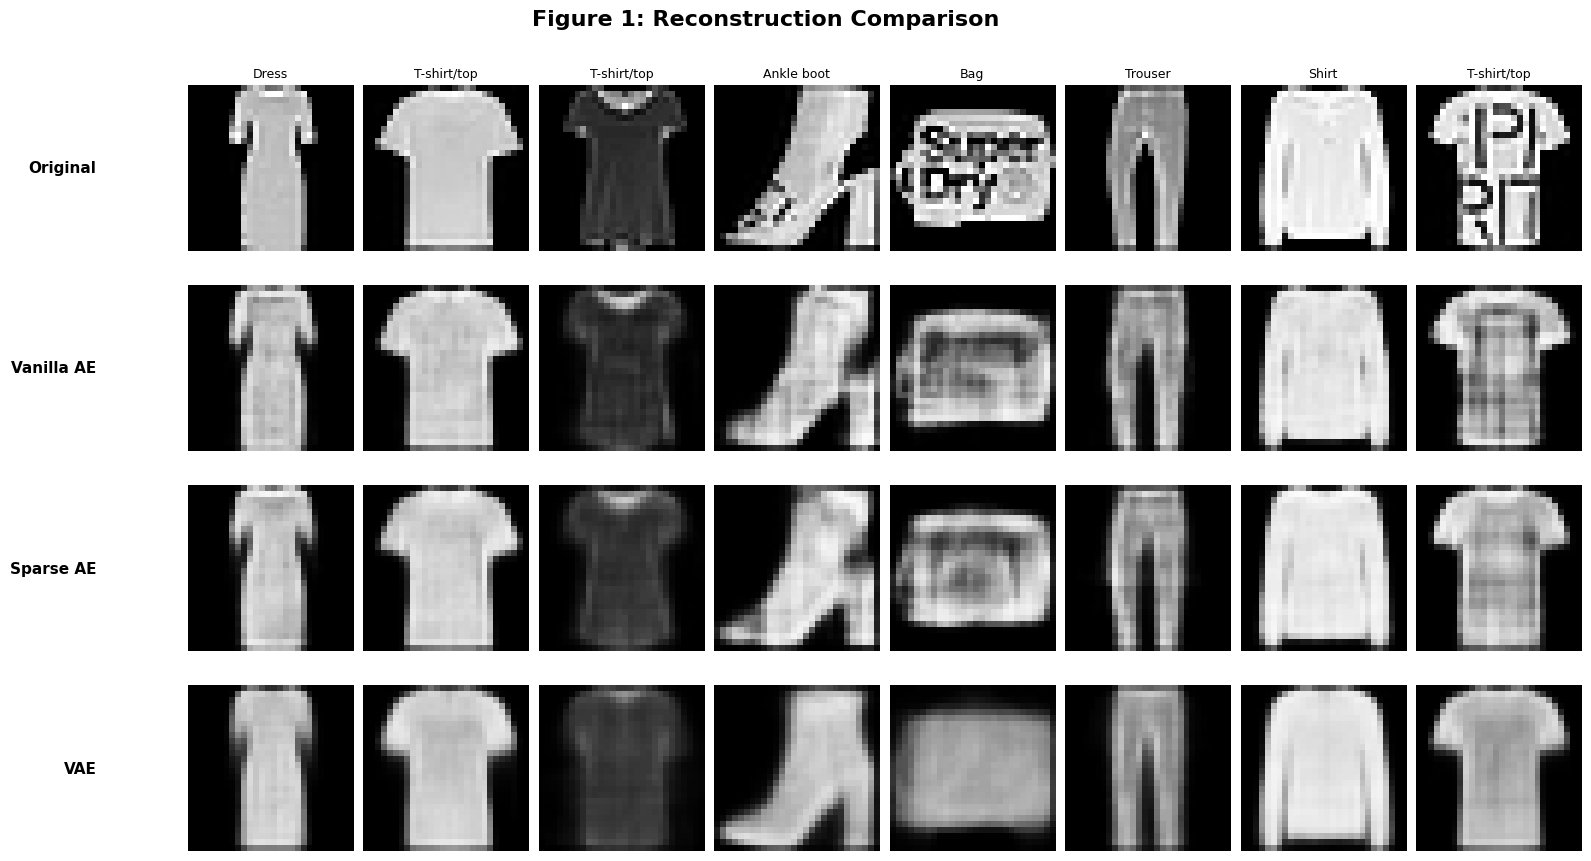

Figure 1 completed!
Saved to: outputs/figure_1_reconstruction.png


In [54]:
# F1
# Reconstruction Comparison(Original vs Vanilla AE vs Sparse AE vs VAE)

os.makedirs("outputs", exist_ok=True)

vanilla_ae.eval()
sparse_ae.eval()
vae.eval()

fig1_images, fig1_labels = next(iter(test_loader))
fig1_images = fig1_images[:8].to(DEVICE)
fig1_labels = fig1_labels[:8]

with torch.inference_mode():

    ae_recon = vanilla_ae(fig1_images)

    sparse_recon, _ = sparse_ae(fig1_images)

    vae_hidden = vae.encoder(fig1_images)
    vae_mu = vae.fc_mu(vae_hidden)

    vae_recon = vae.decoder(vae_mu).view(
        -1, 1, 28, 28
    )

rows = [
    ("Original", fig1_images),
    ("Vanilla AE", ae_recon),
    ("Sparse AE", sparse_recon),
    ("VAE", vae_recon)
]

fig, axes = plt.subplots(
    4, 8, figsize=(17, 9)
)

for row_idx, (row_name, batch) in enumerate(rows):

    for col_idx in range(8):

        image = (
            batch[col_idx, 0]
            .detach()
            .cpu()
            .numpy()
        )

        ax = axes[row_idx, col_idx]

        ax.imshow(
            image,
            cmap="gray",
            vmin=0,
            vmax=1
        )

        ax.axis("off")

        if row_idx == 0:
            label = fig1_labels[col_idx].item()
            ax.set_title(
                class_names[label],
                fontsize=9
            )

    axes[row_idx, 0].text(
        -0.55, 0.5,
        row_name,
        transform=axes[row_idx, 0].transAxes,
        fontsize=11,
        fontweight="bold",
        ha="right",
        va="center",
        clip_on=False
    )

fig.suptitle(
    "Figure 1: Reconstruction Comparison",
    fontsize=16,
    fontweight="bold"
)

fig.subplots_adjust(
    left=0.16,
    right=0.98,
    top=0.90,
    bottom=0.04,
    wspace=0.06,
    hspace=0.15
)

save_path = "outputs/figure_1_reconstruction.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 1 completed!")
print("Saved to:", save_path)




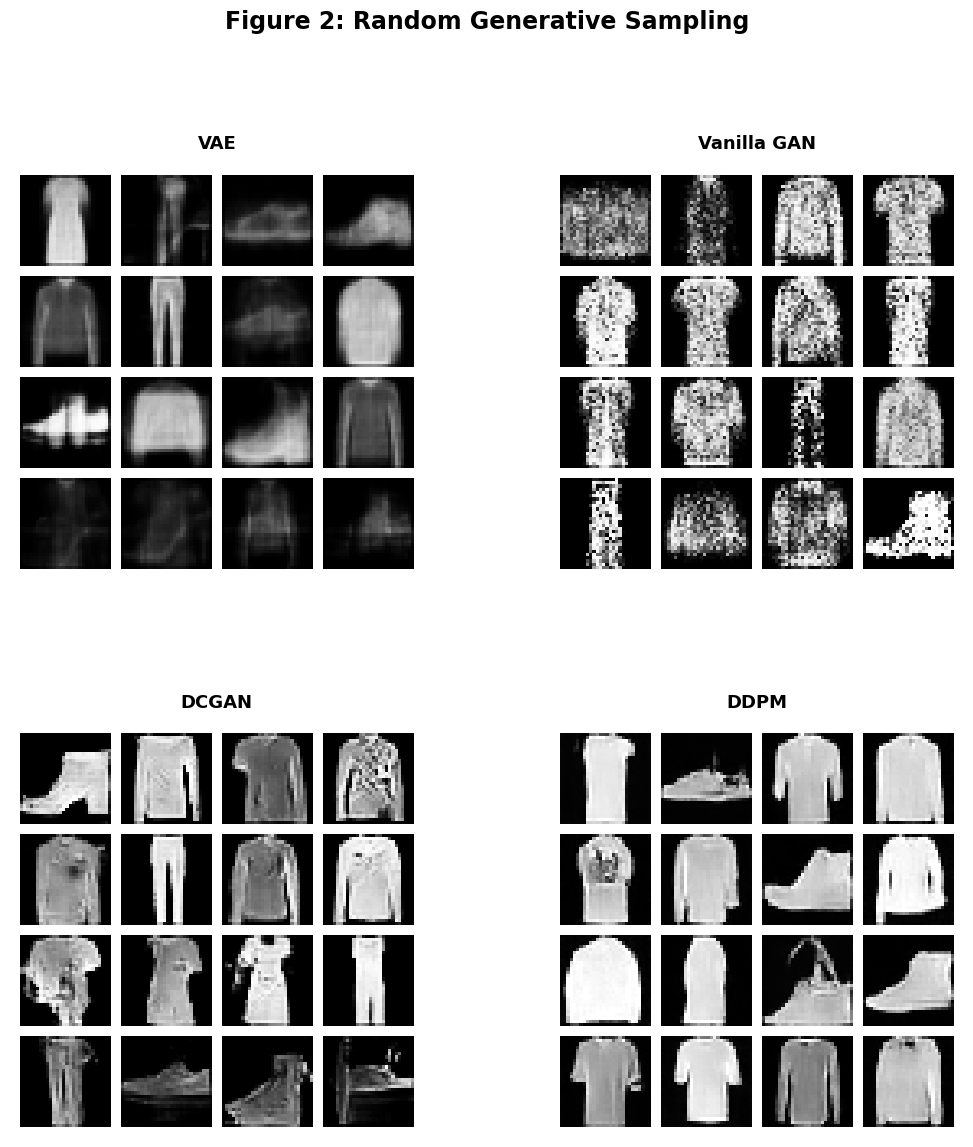

Figure 2 completed!
Saved to: outputs/figure_2_random_sampling.png


In [55]:
# F2
# Random Generative Sampling

os.makedirs("outputs", exist_ok=True)

vae.eval()
generator.eval()
dc_generator.eval()
ddpm_model.eval()

N_SAMPLES = 16

fig2_rng = torch.Generator(device=DEVICE)
fig2_rng.manual_seed(SEED + 2026)

assert "ddpm_generated_images" in globals(), (
    "Run the 'Generate Image 16' cell first."
)

with torch.inference_mode():

    z_vae = torch.randn(
        N_SAMPLES, LATENT_DIM,
        device=DEVICE, generator=fig2_rng
    )

    z_gan = torch.randn(
        N_SAMPLES, GAN_LATENT_DIM,
        device=DEVICE, generator=fig2_rng
    )

    z_dcgan = torch.randn(
        N_SAMPLES, DCGAN_LATENT_DIM,
        device=DEVICE, generator=fig2_rng
    )

    samples = {
        "VAE": vae.decoder(z_vae).reshape(
            N_SAMPLES, 1, 28, 28
        ),

        "Vanilla GAN": generator(z_gan),

        "DCGAN": dc_generator(z_dcgan),

        "DDPM": ddpm_generated_images[:N_SAMPLES]
    }


fig, axes = plt.subplots(
    2, 2, figsize=(11, 12)
)

for ax, (model_name, images) in zip(
    axes.flat, samples.items()
):
    assert images.shape == (16, 1, 28, 28)
    assert torch.isfinite(images).all()

    grid = make_grid(
        images.detach().cpu().clamp(0, 1),
        nrow=4,
        padding=3,
        pad_value=1
    )

    ax.imshow(
        grid[0].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax.set_title(
        model_name, fontsize=13,
        fontweight="bold", pad=12
    )

    ax.axis("off")

fig.suptitle(
    "Figure 2: Random Generative Sampling",
    fontsize=17,
    fontweight="bold",
    y=0.99
)

fig.subplots_adjust(
    left=0.05,
    right=0.95,
    bottom=0.05,
    top=0.86,
    wspace=0.20,
    hspace=0.35
)

save_path = "outputs/figure_2_random_sampling.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 2 completed!")
print("Saved to:", save_path)


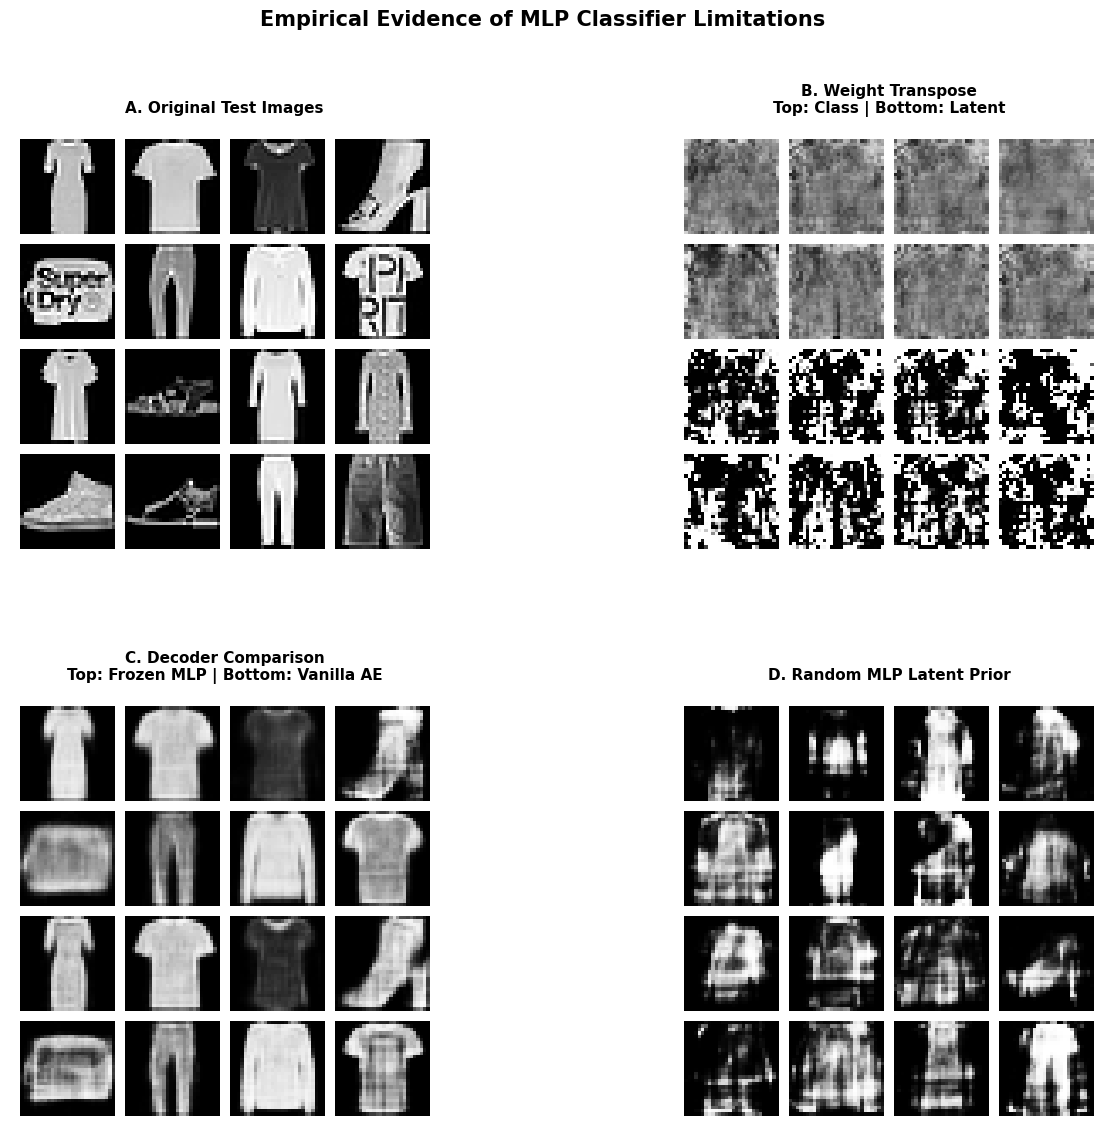

Figure 3 completed!
Saved to: outputs/figure_3_mlp_limitations.png


In [56]:
# F3
# MLP Classifier Limitations

os.makedirs("outputs", exist_ok=True)

mlp_classifier.eval()
mlp_decoder.eval()
vanilla_ae.eval()


fig3_images, fig3_labels = next(iter(test_loader))
fig3_images = fig3_images[:16].to(DEVICE)
fig3_labels = fig3_labels[:16].to(DEVICE)

with torch.inference_mode():

    W1 = mlp_classifier.fc1.weight.detach()
    W2 = mlp_classifier.fc2.weight.detach()
    W3 = mlp_classifier.fc3.weight.detach()

    class_vectors = F.one_hot(
        fig3_labels[:8],
        num_classes=10
    ).float()

    z_class = F.relu(class_vectors @ W3)
    h_class = F.relu(z_class @ W2)

    class_projection = torch.sigmoid(
        h_class @ W1
    ).view(-1, 1, 28, 28)

    z_mlp = mlp_classifier.extract_features(
        fig3_images[:8]
    )

    h_latent = F.relu(z_mlp @ W2)

    latent_projection = torch.sigmoid(
        h_latent @ W1
    ).view(-1, 1, 28, 28)

    frozen_reconstruction = mlp_decoder(z_mlp)

    ae_reconstruction = vanilla_ae(
        fig3_images[:8]
    )

    prior_samples = generated_mlp_images[:16]

fig3_panels = {
    "A. Original Test Images":
        fig3_images,

    "B. Weight Transpose\nTop: Class | Bottom: Latent":
        torch.cat([
            class_projection,
            latent_projection
        ], dim=0),

    "C. Decoder Comparison\nTop: Frozen MLP | Bottom: Vanilla AE":
        torch.cat([
            frozen_reconstruction,
            ae_reconstruction
        ], dim=0),

    "D. Random MLP Latent Prior":
        prior_samples
}

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 12)
)

for ax, (title, images) in zip(
    axes.flat,
    fig3_panels.items()
):

    assert images.shape == (16, 1, 28, 28)
    assert torch.isfinite(images).all()

    grid = make_grid(
        images.detach().cpu().clamp(0, 1),
        nrow=4,
        padding=3,
        pad_value=1
    )

    ax.imshow(
        grid[0].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(
        title,
        fontsize=11,
        fontweight="bold",
        pad=12
    )

    ax.axis("off")

fig.suptitle(
    "Empirical Evidence of MLP Classifier Limitations",
    fontsize=15,
    fontweight="bold",
    y=0.98
)

fig.subplots_adjust(
    left=0.07,
    right=0.95,
    top=0.88,
    bottom=0.05,
    wspace=0.17,
    hspace=0.32
)

save_path = "outputs/figure_3_mlp_limitations.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 3 completed!")
print("Saved to:", save_path)


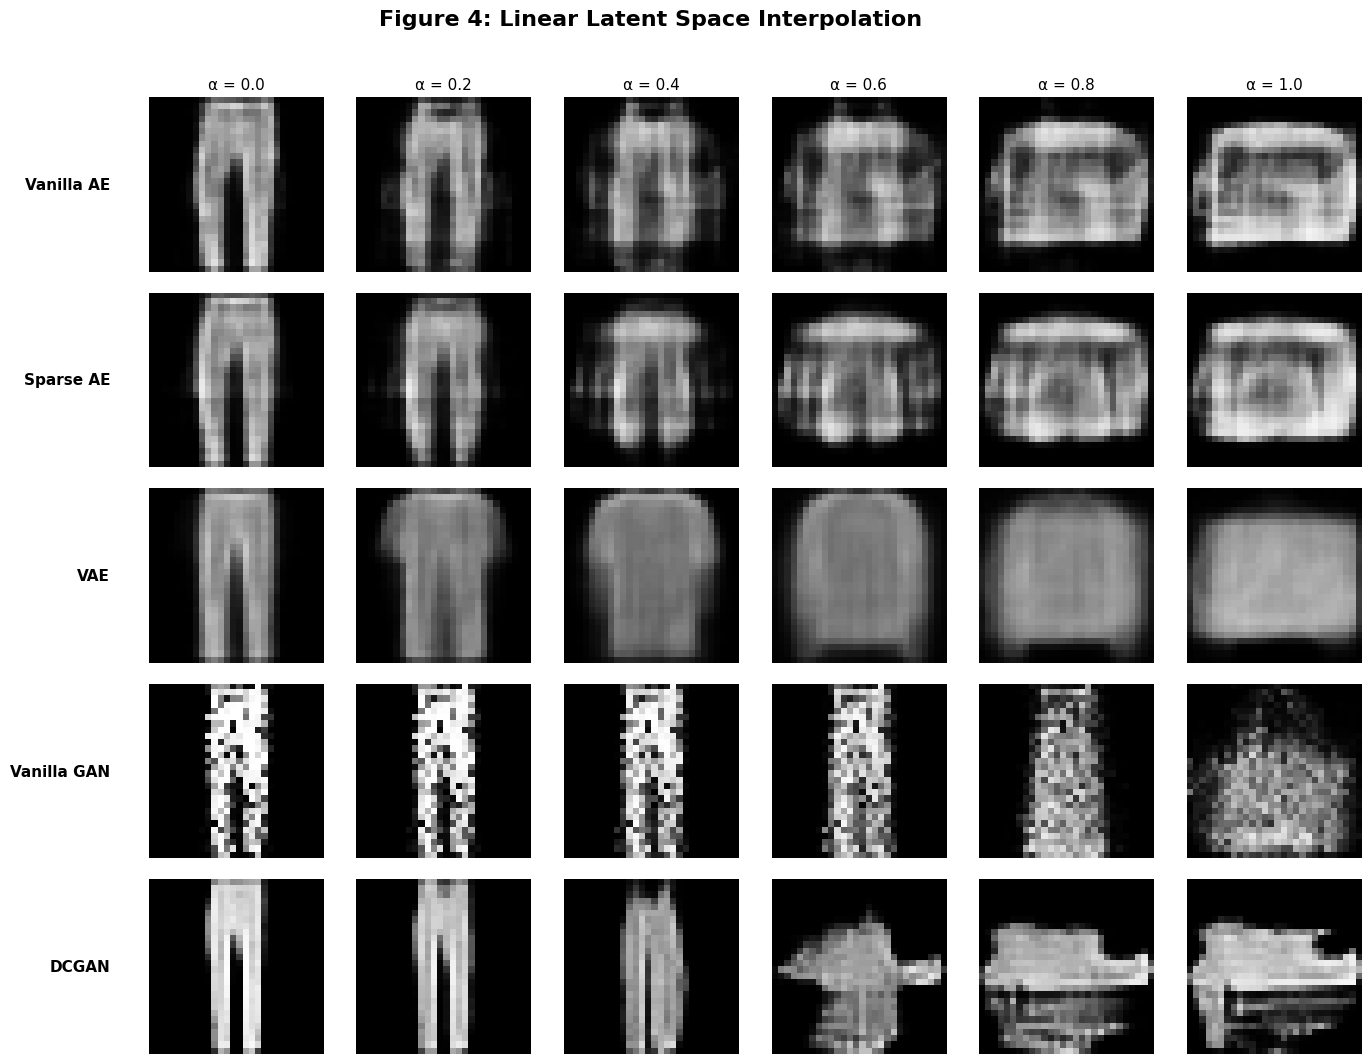

Figure 4 completed!
Saved to: outputs/figure_4_interpolation.png


In [57]:
# F4
# Final Visualization and Export

assert "interpolation_results" in globals(), (
    "Run the original interpolation cell first."
)

model_names = [
    "Vanilla AE",
    "Sparse AE",
    "VAE",
    "Vanilla GAN",
    "DCGAN"
]

alpha_values = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

fig, axes = plt.subplots(5, 6, figsize=(15, 11))

for row, model_name in enumerate(model_names):
    images = interpolation_results[model_name]

    for col, img in enumerate(images):
        ax = axes[row, col]
        ax.imshow(img, cmap="gray", vmin=0, vmax=1)
        ax.axis("off")

        if row == 0:
            ax.set_title(
                f"α = {alpha_values[col]:.1f}",
                fontsize=11
            )

fig.subplots_adjust(
    left=0.16,
    right=0.98,
    top=0.90,
    bottom=0.03,
    wspace=0.08,
    hspace=0.12
)

for row, model_name in enumerate(model_names):
    pos = axes[row, 0].get_position()

    fig.text(
        0.14,
        (pos.y0 + pos.y1) / 2,
        model_name,
        ha="right",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

fig.suptitle(
    "Figure 4: Linear Latent Space Interpolation",
    fontsize=16,
    fontweight="bold",
    y=0.98
)

os.makedirs("outputs", exist_ok=True)

save_path = "outputs/figure_4_interpolation.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure 4 completed!")
print("Saved to:", save_path)


In [58]:
# Summary

model_metrics = {
    "Vanilla AE": (test_mse, test_psnr, test_ssim),
    "Sparse AE": (sparse_test_mse, sparse_test_psnr, sparse_test_ssim),
    "VAE": (vae_test_mse, vae_test_psnr, vae_test_ssim),
}
latent_dimensions = {
    "Vanilla AE": "64",
    "Sparse AE": "64",
    "VAE": "64",
    "Vanilla GAN": "100",
    "DCGAN": "100",
    "DDPM": "28 x 28 (image noise)",
}
fid_scores = dict(zip(fid_df["Model"], fid_df["FID"]))

report_metrics = benchmark_results.copy()
report_metrics.insert(
    1, "Latent Dimension",
    report_metrics["Model"].map(latent_dimensions)
)
report_metrics["Test MSE"] = report_metrics["Model"].map(
    {name: values[0] for name, values in model_metrics.items()}
)
report_metrics["Test PSNR (dB)"] = report_metrics["Model"].map(
    {name: values[1] for name, values in model_metrics.items()}
)
report_metrics["Test SSIM"] = report_metrics["Model"].map(
    {name: values[2] for name, values in model_metrics.items()}
)
report_metrics["FID-2048 (1,000 samples)"] = report_metrics["Model"].map(
    fid_scores
)

report_metrics.to_csv("outputs/report_metrics.csv", index=False)
print("Report Metrics")
display(report_metrics.round(4).fillna("N/A"))

components = [
    ("Vanilla AE", "Autoencoder", vanilla_ae),
    ("Sparse AE", "Autoencoder", sparse_ae),
    ("VAE", "Encoder + Decoder", vae),
    ("Vanilla GAN", "Generator", generator),
    ("Vanilla GAN", "Discriminator", discriminator),
    ("DCGAN", "Generator", dc_generator),
    ("DCGAN", "Discriminator", dc_discriminator),
    ("DDPM", "Noise Predictor", ddpm_model),
    ("MLP Classifier", "Classifier", mlp_classifier),
    ("MLP Classifier", "Frozen Latent Decoder", mlp_decoder),
]
parameter_table = pd.DataFrame([
    {
        "Model": name,
        "Component": component,
        "Total Parameters": sum(p.numel() for p in module.parameters()),
    }
    for name, component, module in components
])
parameter_table.to_csv("outputs/model_parameters.csv", index=False)

print("Model Parameters")
display(parameter_table)
print("MLP Classifier Test Accuracy:", f"{mlp_test_accuracy * 100:.2f}%")
print("Frozen MLP Decoder Test MSE:", round(mlp_decoder_test_mse, 6))
print("Frozen MLP Decoder Test PSNR:", round(mlp_decoder_test_psnr, 4))
print("Frozen MLP Decoder Test SSIM:", round(mlp_decoder_test_ssim, 6))
print("Saved: outputs/report_metrics.csv and outputs/model_parameters.csv")


Report Metrics


,Model,Latent Dimension,Average Training Time / Epoch (s),Median Inference Latency / Batch 64 (ms),Latency Std (ms),Test MSE,Test PSNR (dB),Test SSIM,"FID-2048 (1,000 samples)"
0,Vanilla AE,64,8.4364,0.4610,0.0709,0.0071,22.560499,0.815,N/A
1,Sparse AE,64,7.6989,0.4048,0.1012,0.01,20.9573,0.7558,N/A
2,VAE,64,8.1305,0.2706,0.0312,0.0179,18.137699,0.6324,108.6526
3,Vanilla GAN,100,8.2300,0.3619,0.3667,N/A,N/A,N/A,183.9383
4,DCGAN,100,13.8675,2.6133,0.0181,N/A,N/A,N/A,47.367
5,DDPM,28 x 28 (image noise),24.9245,15035.6986,159.9476,N/A,N/A,N/A,71.3775


Model Parameters


,Model,Component,Total Parameters
0,Vanilla AE,Autoencoder,435536
1,Sparse AE,Autoencoder,435536
2,VAE,Encoder + Decoder,451984
3,Vanilla GAN,Generator,559632
4,Vanilla GAN,Discriminator,533505
5,DCGAN,Generator,759681
6,DCGAN,Discriminator,138625
7,DDPM,Noise Predictor,940193
8,MLP Classifier,Classifier,218058
9,MLP Classifier,Frozen Latent Decoder,218128


MLP Classifier Test Accuracy: 89.33%
Frozen MLP Decoder Test MSE: 0.018117
Frozen MLP Decoder Test PSNR: 18.1858
Frozen MLP Decoder Test SSIM: 0.650995
Saved: outputs/report_metrics.csv and outputs/model_parameters.csv
